In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/prksh830/hdp-2807/heart_disease_dataset_self.csv
/kaggle/input/datasets/prksh830/hdp-2807/heart.csv


In [2]:
# ============================================================
# List all files available in Kaggle Input
# ============================================================

import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    print(f"\n📁 {dirname}")
    for filename in filenames:
        print("   └──", filename)


📁 /kaggle/input

📁 /kaggle/input/datasets

📁 /kaggle/input/datasets/prksh830

📁 /kaggle/input/datasets/prksh830/hdp-2807
   └── heart_disease_dataset_self.csv
   └── heart.csv


In [3]:
# ============================================================
# SECTION 1 : Import Libraries
# ============================================================

import warnings
warnings.filterwarnings("ignore")

import os
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import *

import tensorflow as tf

print("="*70)
print("TensorFlow :", tf.__version__)
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)
print("="*70)

TensorFlow : 2.20.0
NumPy      : 2.0.2
Pandas     : 2.3.3


In [4]:
# ============================================================
# SECTION 2 : Reproducibility
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random Seed Fixed :", SEED)

Random Seed Fixed : 42


In [5]:
TRAIN_PATH = "/kaggle/input/datasets/prksh830/hdp-2807/heart_disease_dataset_self.csv"

TEST_PATH = "/kaggle/input/datasets/prksh830/hdp-2807/heart.csv"

In [6]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training Shape :", train_df.shape)
print("Testing Shape  :", test_df.shape)

Training Shape : (2283, 14)
Testing Shape  : (1025, 14)


In [7]:
# ============================================================
# SECTION 2 : Final Dataset Verification
# ============================================================

print("="*80)
print("FINAL TRAINING DATASET")
print("="*80)

print("Shape :", train_df.shape)

print("\nColumns\n")

for i, col in enumerate(train_df.columns):
    print(f"{i+1:02d}. {col}")

print("\n")

print("="*80)
print("EXTERNAL TEST DATASET")
print("="*80)

print("Shape :", test_df.shape)

FINAL TRAINING DATASET
Shape : (2283, 14)

Columns

01. age
02. sex
03. cp
04. trestbps
05. chol
06. fbs
07. restecg
08. thalach
09. exang
10. oldpeak
11. slope
12. ca
13. thal
14. target


EXTERNAL TEST DATASET
Shape : (1025, 14)


In [8]:
# ============================================================
# Missing Value Analysis
# ============================================================

missing = train_df.isnull().sum()

missing = missing[missing > 0]

print(missing)

print("\nTotal Missing Values :", missing.sum())

trestbps      60
chol         352
fbs           90
restecg        2
thalach       55
exang         55
oldpeak       62
slope        307
ca          1672
thal        1547
dtype: int64

Total Missing Values : 4202


In [9]:
# ============================================================
# Duplicate Analysis
# ============================================================

print("Training Duplicates :", train_df.duplicated().sum())

print("Testing Duplicates  :", test_df.duplicated().sum())

Training Duplicates : 0
Testing Duplicates  : 723


In [10]:
# ============================================================
# Target Distribution
# ============================================================

print(train_df['target'].value_counts())

print()

print(train_df['target'].value_counts(normalize=True)*100)

target
1    1222
0    1061
Name: count, dtype: int64

target
1    53.526062
0    46.473938
Name: proportion, dtype: float64


In [11]:
# ============================================================
# Feature Compatibility
# ============================================================

train_cols = set(train_df.columns)
test_cols = set(test_df.columns)

print("Missing in Training")

print(test_cols-train_cols)

print()

print("Missing in Testing")

print(train_cols-test_cols)

Missing in Training
set()

Missing in Testing
set()


In [12]:
# ============================================================
# SECTION 3.1 : Feature and Target Separation
# ============================================================

TARGET = 'target'

X = train_df.drop(columns=[TARGET]).copy()
y = train_df[TARGET].copy()

X_external = test_df.drop(columns=[TARGET]).copy()
y_external = test_df[TARGET].copy()

print("="*70)
print("Training Feature Matrix :", X.shape)
print("Training Target         :", y.shape)
print("External Feature Matrix :", X_external.shape)
print("External Target         :", y_external.shape)
print("="*70)

Training Feature Matrix : (2283, 13)
Training Target         : (2283,)
External Feature Matrix : (1025, 13)
External Target         : (1025,)


In [13]:
# ============================================================
# SECTION 3.2 : Feature Types
# ============================================================

continuous_features = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

print("Continuous Features :", len(continuous_features))
print(continuous_features)

print("\nCategorical Features :", len(categorical_features))
print(categorical_features)

Continuous Features : 5
['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical Features : 8
['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [14]:
# ============================================================
# SECTION 3.3 : Verify Categories
# ============================================================

for col in categorical_features:
    print("="*60)
    print(col)
    print("Training :", sorted(X[col].dropna().unique()))
    print("Testing  :", sorted(X_external[col].dropna().unique()))

sex
Training : [np.int64(0), np.int64(1)]
Testing  : [np.int64(0), np.int64(1)]
cp
Training : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Testing  : [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
fbs
Training : [np.float64(0.0), np.float64(1.0)]
Testing  : [np.int64(0), np.int64(1)]
restecg
Training : [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
Testing  : [np.int64(0), np.int64(1), np.int64(2)]
exang
Training : [np.float64(0.0), np.float64(1.0)]
Testing  : [np.int64(0), np.int64(1)]
slope
Training : [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
Testing  : [np.int64(0), np.int64(1), np.int64(2)]
ca
Training : [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
Testing  : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
thal
Training : [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(6.0), np.float64(7.0)]
Testing  : [np.int64(0), np.int64(1), np.int64(2), np.in

In [15]:
# ============================================================
# SECTION 3.4 : Train/Validation Split
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("="*70)
print("Training :", X_train.shape)
print("Validation :", X_valid.shape)
print("External :", X_external.shape)
print("="*70)

Training : (1826, 13)
Validation : (457, 13)
External : (1025, 13)


In [16]:
# ============================================================
# SECTION 3.5 : Missing Value Imputation
# ============================================================

from sklearn.impute import SimpleImputer

continuous_imputer = SimpleImputer(strategy='median')
categorical_imputer = SimpleImputer(strategy='most_frequent')

# Continuous
X_train[continuous_features] = continuous_imputer.fit_transform(
    X_train[continuous_features]
)

X_valid[continuous_features] = continuous_imputer.transform(
    X_valid[continuous_features]
)

X_external[continuous_features] = continuous_imputer.transform(
    X_external[continuous_features]
)

# Categorical
X_train[categorical_features] = categorical_imputer.fit_transform(
    X_train[categorical_features]
)

X_valid[categorical_features] = categorical_imputer.transform(
    X_valid[categorical_features]
)

X_external[categorical_features] = categorical_imputer.transform(
    X_external[categorical_features]
)

print("Missing values after imputation")
print("--------------------------------")

print("Training :", X_train.isnull().sum().sum())
print("Validation :", X_valid.isnull().sum().sum())
print("External :", X_external.isnull().sum().sum())

Missing values after imputation
--------------------------------
Training : 0
Validation : 0
External : 0


In [17]:
# ============================================================
# SECTION 3.6 : Robust Feature Scaling
# ============================================================

from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_train[continuous_features] = scaler.fit_transform(
    X_train[continuous_features]
)

X_valid[continuous_features] = scaler.transform(
    X_valid[continuous_features]
)

X_external[continuous_features] = scaler.transform(
    X_external[continuous_features]
)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


In [18]:
# ============================================================
# SECTION 3.7 : Final Verification
# ============================================================

print("="*70)

print("Training :", X_train.shape)
print("Validation :", X_valid.shape)
print("External :", X_external.shape)

print("="*70)

print("Training Missing :", X_train.isnull().sum().sum())
print("Validation Missing :", X_valid.isnull().sum().sum())
print("External Missing :", X_external.isnull().sum().sum())

Training : (1826, 13)
Validation : (457, 13)
External : (1025, 13)
Training Missing : 0
Validation Missing : 0
External Missing : 0


In [19]:
# ============================================================
# SECTION 4.1 : ARO Parameters
# ============================================================

ARO_CONFIG = {

    "population": 20,

    "iterations": 30,

    "feature_count": 13,

    "mutation_probability": 0.15,

    "elite_fraction": 0.20,

    "random_seed": 42

}

print(ARO_CONFIG)

{'population': 20, 'iterations': 30, 'feature_count': 13, 'mutation_probability': 0.15, 'elite_fraction': 0.2, 'random_seed': 42}


In [20]:
# ============================================================
# SECTION 4.2 : Search Space
# ============================================================

SEARCH_SPACE = {

    "learning_rate": (1e-5,1e-2),

    "batch_size":[16,32,64,128],

    "hidden1":(64,512),

    "hidden2":(32,256),

    "hidden3":(16,128),

    "dropout":(0.10,0.60),

    "l2":(1e-6,1e-3)

}

In [21]:
# ============================================================
# SECTION 4.3 : Rabbit Initialization
# ============================================================

def initialize_rabbit():

    rabbit = {}

    rabbit['features'] = np.random.randint(
        0,
        2,
        len(X_train.columns)
    )

    if rabbit['features'].sum() == 0:
        rabbit['features'][np.random.randint(len(X_train.columns))] = 1

    rabbit['learning_rate'] = np.random.uniform(1e-5,1e-2)

    rabbit['batch_size'] = random.choice([16,32,64,128])

    rabbit['hidden1'] = random.randint(64,512)

    rabbit['hidden2'] = random.randint(32,256)

    rabbit['hidden3'] = random.randint(16,128)

    rabbit['dropout'] = np.random.uniform(0.10,0.60)

    rabbit['l2'] = np.random.uniform(1e-6,1e-3)

    rabbit['fitness'] = -999

    return rabbit

In [22]:
# ============================================================
# SECTION 4.4 : Population Initialization
# ============================================================

population = []

for _ in range(ARO_CONFIG['population']):

    population.append(
        initialize_rabbit()
    )

print("Population Created :",len(population))

Population Created : 20


In [23]:
# ============================================================
# SECTION 4.1 : Deep Learning Libraries
# ============================================================

from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    LayerNormalization,
    BatchNormalization,
    Add,
    Multiply,
    Concatenate
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

In [24]:
# ============================================================
# Clinical Feature Embedding
# ============================================================

def ClinicalFeatureEmbedding(x, units):

    x = Dense(
        units,
        activation='relu'
    )(x)

    x = BatchNormalization()(x)

    return x

In [25]:
# ============================================================
# Adaptive Feature Gating
# ============================================================

def AdaptiveFeatureGate(x):

    gate = Dense(
        x.shape[-1],
        activation='sigmoid'
    )(x)

    x = Multiply()([x, gate])

    return x

In [26]:
# ============================================================
# Residual Interaction Block
# ============================================================

def ResidualInteraction(x, units, dropout):

    shortcut = x

    y = Dense(
        units,
        activation='relu'
    )(x)

    y = BatchNormalization()(y)

    y = Dropout(dropout)(y)

    y = Dense(units)(y)

    if shortcut.shape[-1] != units:
        shortcut = Dense(units)(shortcut)

    out = Add()([shortcut, y])

    out = LayerNormalization()(out)

    return out

In [27]:
# ============================================================
# Dense Fusion
# ============================================================

def DenseFusion(x, dropout):

    x1 = Dense(128, activation='relu')(x)

    x2 = Dense(64, activation='relu')(x1)

    x3 = Dense(32, activation='relu')(x2)

    fusion = Concatenate()([x1, x2, x3])

    fusion = Dropout(dropout)(fusion)

    return fusion

In [28]:
# ============================================================
# FTAMNet
# ============================================================

def build_ftamnet(
    input_dim,
    hidden1=256,
    hidden2=128,
    hidden3=64,
    dropout=0.30,
    learning_rate=1e-3,
    l2_weight=1e-4
):

    inputs = Input(shape=(input_dim,))

    x = ClinicalFeatureEmbedding(inputs, hidden1)

    x = AdaptiveFeatureGate(x)

    x = ResidualInteraction(
        x,
        hidden2,
        dropout
    )

    x = ResidualInteraction(
        x,
        hidden3,
        dropout
    )

    x = DenseFusion(
        x,
        dropout
    )

    outputs = Dense(
        1,
        activation='sigmoid',
        kernel_regularizer=l2(l2_weight)
    )(x)

    model = Model(inputs, outputs)

    model.compile(

        optimizer=Adam(
            learning_rate=learning_rate
        ),

        loss='binary_crossentropy',

        metrics=[
            'accuracy',
            tf.keras.metrics.AUC(name='auc')
        ]
    )

    return model

In [29]:
# ============================================================
# Create FTAMNet
# ============================================================

model = build_ftamnet(
    input_dim=X_train.shape[1]
)

model.summary()

2026-07-28 19:39:05.128653: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 13)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │      3,584 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │     65,792 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 256)       │          0 │ batch_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     32,896 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_2[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 128)       │     32,896 │ multiply[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 128)       │     16,512 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128)       │          0 │ dense_4[0][0],    │
│                     │                   │            │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 128)       │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 64)        │      8,256 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_5[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64)        │      8,256 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      4,160 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64)        │          0 │ dense_7[0][0],    │
│                     │                   │            │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 64)        │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 128)       │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 193,409 (755.50 KB)

 Trainable params: 192,513 (752.00 KB)

 Non-trainable params: 896 (3.50 KB)

In [30]:
# ============================================================
# SECTION 5.1 : Training Callbacks
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "FTAMNet_Best.keras",
    monitor='val_auc',
    mode='max',
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stop,
    reduce_lr,
    checkpoint
]

In [31]:
# ============================================================
# SECTION 5.2 : Model Training
# ============================================================

history = model.fit(

    X_train,
    y_train,

    validation_data=(
        X_valid,
        y_valid
    ),

    epochs=100,

    batch_size=32,

    callbacks=callbacks,

    verbose=1
)

Epoch 1/100
55/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6634 - auc: 0.6944 - loss: 0.6388
Epoch 1: val_auc improved from None to 0.79678, saving model to FTAMNet_Best.keras

Epoch 1: finished saving model to FTAMNet_Best.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.7059 - auc: 0.7675 - loss: 0.5816 - val_accuracy: 0.5646 - val_auc: 0.7968 - val_loss: 1.0114 - learning_rate: 0.0010
Epoch 2/100
53/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7444 - auc: 0.8395 - loss: 0.4976
Epoch 2: val_auc improved from 0.79678 to 0.82874, saving model to FTAMNet_Best.keras

Epoch 2: finished saving model to FTAMNet_Best.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7552 - auc: 0.8429 - loss: 0.4929 - val_accuracy: 0.7462 - val_auc: 0.8287 - val_loss: 0.6029 - learning_rate: 0.0010
Epoch 3/100
55/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7909 - auc: 0.8720 - loss: 0.4488
Epoch 3: val_auc improved from 0.82874 to 0.84302, saving model to FTAMNet_Best.ker

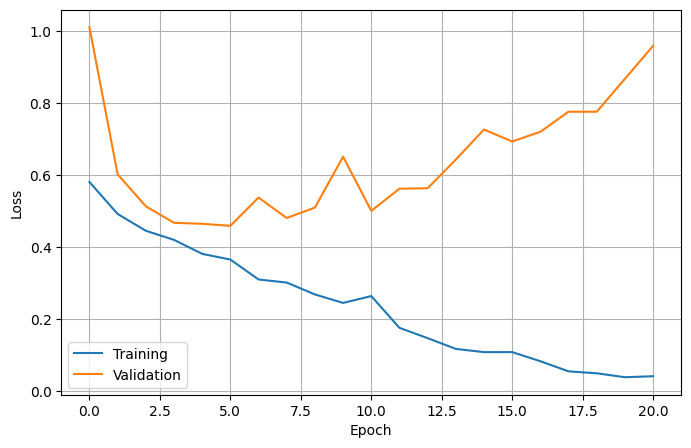

In [32]:
# ============================================================
# SECTION 5.3 : Learning Curves
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training')

plt.plot(history.history['val_loss'], label='Validation')

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

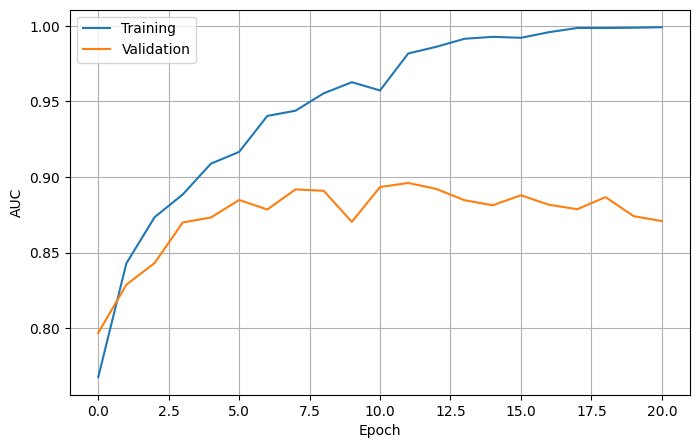

In [33]:
# ============================================================
# Validation AUC
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(history.history['auc'], label='Training')

plt.plot(history.history['val_auc'], label='Validation')

plt.xlabel("Epoch")

plt.ylabel("AUC")

plt.legend()

plt.grid(True)

plt.show()

In [34]:
# ============================================================
# SECTION 6.1 : Validation Prediction
# ============================================================

valid_prob = model.predict(X_valid)

valid_pred = (valid_prob >= 0.5).astype(int)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix
)

acc = accuracy_score(y_valid, valid_pred)
prec = precision_score(y_valid, valid_pred)
rec = recall_score(y_valid, valid_pred)
f1 = f1_score(y_valid, valid_pred)
auc = roc_auc_score(y_valid, valid_prob)
mcc = matthews_corrcoef(y_valid, valid_pred)

print("="*50)
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"AUROC    : {auc:.4f}")
print(f"MCC      : {mcc:.4f}")
print("="*50)

Accuracy : 0.8184
Precision: 0.8293
Recall   : 0.8327
F1 Score : 0.8310
AUROC    : 0.8841
MCC      : 0.6347


In [36]:
# ============================================================
# SECTION 7.1 : External Dataset Prediction
# ============================================================

external_prob = model.predict(X_external)

external_pred = (external_prob >= 0.5).astype(int)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [37]:
# ============================================================
# SECTION 7.2 : External Performance
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

acc = accuracy_score(y_external, external_pred)
prec = precision_score(y_external, external_pred)
rec = recall_score(y_external, external_pred)
f1 = f1_score(y_external, external_pred)
auc = roc_auc_score(y_external, external_prob)
mcc = matthews_corrcoef(y_external, external_pred)

print("="*60)
print("External Test Performance")
print("="*60)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"AUROC    : {auc:.4f}")
print(f"MCC      : {mcc:.4f}")

External Test Performance
Accuracy : 0.7239
Precision: 0.8809
Recall   : 0.5342
F1 Score : 0.6651
AUROC    : 0.9046
MCC      : 0.4945


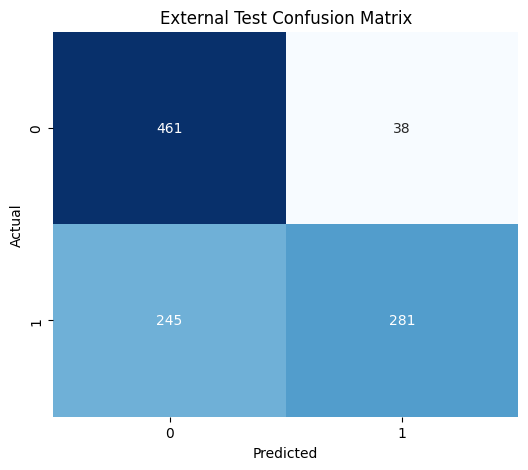

In [38]:
# ============================================================
# SECTION 7.3 : Confusion Matrix
# ============================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_external, external_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("External Test Confusion Matrix")

plt.show()

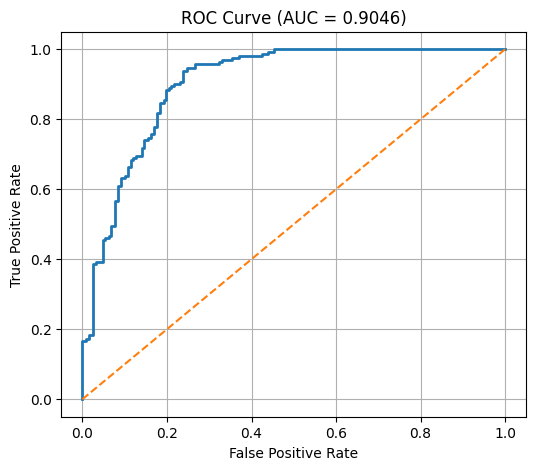

In [39]:
# ============================================================
# SECTION 7.4 : ROC Curve
# ============================================================

from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_external, external_prob)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, linewidth=2)

plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve (AUC = {auc:.4f})")

plt.grid(True)

plt.show()

In [40]:
# ============================================================
# SECTION 8.1 : Threshold Optimization
# ============================================================

import numpy as np
from sklearn.metrics import f1_score, matthews_corrcoef

thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for t in thresholds:

    pred = (valid_prob >= t).astype(int)

    f1 = f1_score(y_valid, pred)
    mcc = matthews_corrcoef(y_valid, pred)

    score = 0.5 * f1 + 0.5 * mcc

    results.append([t, f1, mcc, score])

import pandas as pd

threshold_df = pd.DataFrame(
    results,
    columns=[
        "Threshold",
        "F1",
        "MCC",
        "Score"
    ]
)

best = threshold_df.loc[
    threshold_df.Score.idxmax()
]

print(best)

Threshold    0.460000
F1           0.835700
MCC          0.643372
Score        0.739536
Name: 36, dtype: float64


In [41]:
best_threshold = float(best["Threshold"])

external_pred = (
    external_prob >= best_threshold
).astype(int)

In [42]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

acc = accuracy_score(y_external, external_pred)
prec = precision_score(y_external, external_pred)
rec = recall_score(y_external, external_pred)
f1 = f1_score(y_external, external_pred)
auc = roc_auc_score(y_external, external_prob)   # Use probabilities here
mcc = matthews_corrcoef(y_external, external_pred)

print("="*60)
print(f"Threshold : {best_threshold:.2f}")
print("="*60)
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUROC     : {auc:.4f}")
print(f"MCC       : {mcc:.4f}")

Threshold : 0.46
Accuracy  : 0.7337
Precision : 0.8845
Recall    : 0.5532
F1-score  : 0.6807
AUROC     : 0.9046
MCC       : 0.5108


In [43]:
# ============================================================
# SECTION 9.1 : Search Space
# ============================================================

SEARCH_SPACE = {

    "hidden1": (128,512),

    "hidden2": (64,256),

    "hidden3": (32,128),

    "dropout": (0.10,0.50),

    "learning_rate": (1e-4,5e-3),

    "l2": (1e-6,1e-3),

    "batch_size":[16,32,64,128]

}

FEATURE_COUNT = X_train.shape[1]

In [44]:
# ============================================================
# Rabbit Initialization
# ============================================================

def initialize_rabbit():

    rabbit={}

    rabbit["feature_mask"]=np.random.randint(
        0,
        2,
        FEATURE_COUNT
    )

    if rabbit["feature_mask"].sum()==0:

        rabbit["feature_mask"][
            np.random.randint(FEATURE_COUNT)
        ]=1

    rabbit["hidden1"]=random.randint(128,512)

    rabbit["hidden2"]=random.randint(64,256)

    rabbit["hidden3"]=random.randint(32,128)

    rabbit["dropout"]=np.random.uniform(0.10,0.50)

    rabbit["learning_rate"]=np.random.uniform(
        1e-4,
        5e-3
    )

    rabbit["l2"]=np.random.uniform(
        1e-6,
        1e-3
    )

    rabbit["batch_size"]=random.choice(
        [16,32,64,128]
    )

    rabbit["fitness"]=-999

    return rabbit

In [45]:
POPULATION_SIZE=12

population=[]

for _ in range(POPULATION_SIZE):

    population.append(
        initialize_rabbit()
    )

print(len(population))

12


In [46]:
from sklearn.metrics import (
    roc_auc_score,
    matthews_corrcoef,
    f1_score
)

BEST_THRESHOLD=0.27

In [47]:
def evaluate_rabbit(rabbit):

    mask=rabbit["feature_mask"].astype(bool)

    Xtr=X_train.iloc[:,mask]

    Xvl=X_valid.iloc[:,mask]

    model=build_ftamnet(

        input_dim=Xtr.shape[1],

        hidden1=rabbit["hidden1"],

        hidden2=rabbit["hidden2"],

        hidden3=rabbit["hidden3"],

        dropout=rabbit["dropout"],

        learning_rate=rabbit["learning_rate"],

        l2_weight=rabbit["l2"]

    )

    model.fit(

        Xtr,
        y_train,

        validation_data=(Xvl,y_valid),

        epochs=10,

        batch_size=rabbit["batch_size"],

        verbose=0
    )

    prob=model.predict(
        Xvl,
        verbose=0
    )

    pred=(prob>=BEST_THRESHOLD).astype(int)

    auc=roc_auc_score(
        y_valid,
        prob
    )

    f1=f1_score(
        y_valid,
        pred
    )

    mcc=matthews_corrcoef(
        y_valid,
        pred
    )

    fitness=(
        0.5*auc+
        0.3*mcc+
        0.2*f1
    )

    rabbit["fitness"]=fitness

    rabbit["auc"]=auc

    rabbit["f1"]=f1

    rabbit["mcc"]=mcc

    return rabbit

In [48]:
for i in range(len(population)):

    population[i]=evaluate_rabbit(
        population[i]
    )

population=sorted(

    population,

    key=lambda x:x["fitness"],

    reverse=True

)

best_rabbit=population[0]

print("="*60)

print("Initial Best Fitness")

print(best_rabbit["fitness"])

print(best_rabbit["auc"])

print(best_rabbit["mcc"])

print(best_rabbit["f1"])

Initial Best Fitness
0.7574324519377605
0.869118213323065
0.5429111509207599
0.8


In [49]:
def update_rabbit(rabbit,best):

    child={}

    feature=rabbit["feature_mask"].copy()

    for i in range(FEATURE_COUNT):

        if np.random.rand()<0.15:

            feature[i]=1-feature[i]

    if feature.sum()==0:

        feature[
            np.random.randint(FEATURE_COUNT)
        ]=1

    child["feature_mask"]=feature

    for key in [
        "hidden1",
        "hidden2",
        "hidden3"
    ]:

        child[key]=int(

            (rabbit[key]+best[key])/2

            +

            np.random.randint(-16,17)

        )

    child["dropout"]=np.clip(

        (rabbit["dropout"]+
         best["dropout"])/2

        +

        np.random.uniform(-0.05,0.05),

        0.10,

        0.50

    )

    child["learning_rate"]=np.clip(

        (rabbit["learning_rate"]+
         best["learning_rate"])/2

        +

        np.random.uniform(-5e-4,5e-4),

        1e-4,

        5e-3

    )

    child["l2"]=np.clip(

        (rabbit["l2"]+
         best["l2"])/2,

        1e-6,

        1e-3

    )

    child["batch_size"]=random.choice(
        [16,32,64,128]
    )

    child["fitness"]=-999

    return child

In [50]:
ITERATIONS=10

history=[]

for iteration in range(ITERATIONS):

    print(f"\nIteration {iteration+1}")

    new_population=[]

    new_population.append(best_rabbit)

    while len(new_population)<POPULATION_SIZE:

        parent=random.choice(population)

        child=update_rabbit(
            parent,
            best_rabbit
        )

        child=evaluate_rabbit(child)

        new_population.append(child)

    population=sorted(

        new_population,

        key=lambda x:x["fitness"],

        reverse=True

    )

    best_rabbit=population[0]

    history.append(
        best_rabbit["fitness"]
    )

    print(

        "Fitness:",

        round(best_rabbit["fitness"],4)

    )


Iteration 1
Fitness: 0.7574

Iteration 2
Fitness: 0.7574

Iteration 3
Fitness: 0.7574

Iteration 4
Fitness: 0.7574

Iteration 5
Fitness: 0.7574

Iteration 6
Fitness: 0.7574

Iteration 7
Fitness: 0.7574

Iteration 8
Fitness: 0.7574

Iteration 9
Fitness: 0.7574

Iteration 10
Fitness: 0.7574


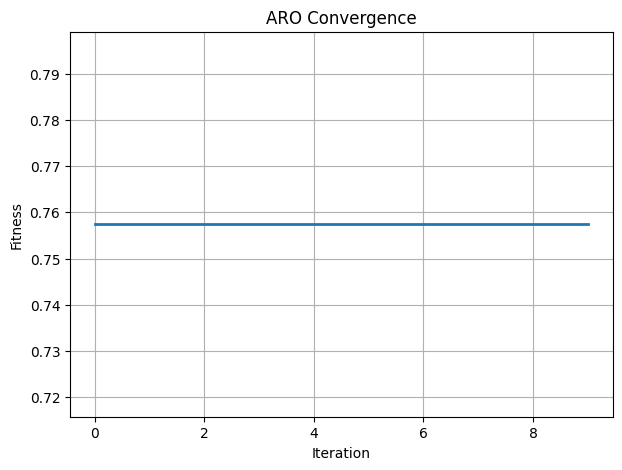

In [51]:
plt.figure(figsize=(7,5))

plt.plot(
    history,
    linewidth=2
)

plt.xlabel("Iteration")

plt.ylabel("Fitness")

plt.title("ARO Convergence")

plt.grid(True)

plt.show()

In [52]:
print("Best fitness:", best_rabbit["fitness"])

for i, rabbit in enumerate(population):
    print(
        i,
        rabbit["fitness"],
        rabbit["hidden1"],
        rabbit["hidden2"],
        rabbit["hidden3"],
        rabbit["dropout"],
        rabbit["learning_rate"]
    )

Best fitness: 0.7574324519377605
0 0.7574324519377605 478 147 39 0.14058861714641285 0.0033511586686294733
1 0.7426063467260369 498 149 37 0.17651068477494716 0.003578944367559609
2 0.7184313762237802 463 158 48 0.12049774263394171 0.0033830456939129214
3 0.7092823603091647 464 129 40 0.1 0.0029883938623901873
4 0.6705395389735859 491 155 41 0.1405459285809641 0.0036454401267038495
5 0.6697106592901068 486 133 39 0.12365058121634803 0.0034161714116608738
6 0.6494535834631314 475 151 31 0.1829157706421679 0.0033100479835539557
7 0.6291733559984292 469 167 33 0.12992212159771552 0.00328752822088528
8 0.5954932935521527 464 142 42 0.14461362844636677 0.0028964064211835666
9 0.5559236480500026 464 153 36 0.17667494575610573 0.003817630094914225
10 0.5185692723228813 486 131 45 0.16907155548514882 0.0037373666477042078
11 0.4888117672484249 494 142 32 0.15138820648031928 0.0033734097968380686


In [53]:
print("="*70)
print("BEST RABBIT")
print("="*70)

for k, v in best_rabbit.items():
    print(k, ":", v)

BEST RABBIT
feature_mask : [0 1 1 0 0 1 1 1 1 1 1 0 1]
hidden1 : 478
hidden2 : 147
hidden3 : 39
dropout : 0.14058861714641285
learning_rate : 0.0033511586686294733
l2 : 6.056522262372468e-06
batch_size : 32
fitness : 0.7574324519377605
auc : 0.869118213323065
f1 : 0.8
mcc : 0.5429111509207599


In [54]:
import pickle

with open("best_rabbit.pkl", "wb") as f:
    pickle.dump(best_rabbit, f)

In [55]:
selected_mask = best_rabbit["feature_mask"].astype(bool)

selected_features = X_train.columns[selected_mask]

print("Selected Features")
print("=================")

for f in selected_features:
    print(f)

print("\nNumber of Selected Features :", len(selected_features))

Selected Features
sex
cp
fbs
restecg
thalach
exang
oldpeak
slope
thal

Number of Selected Features : 9


In [56]:
X_train_final = X_train[selected_features].copy()
X_valid_final = X_valid[selected_features].copy()
X_external_final = X_external[selected_features].copy()

print(X_train_final.shape)
print(X_valid_final.shape)
print(X_external_final.shape)

(1826, 9)
(457, 9)
(1025, 9)


In [57]:
final_model = build_ftamnet(

    input_dim=X_train_final.shape[1],

    hidden1=best_rabbit["hidden1"],

    hidden2=best_rabbit["hidden2"],

    hidden3=best_rabbit["hidden3"],

    dropout=best_rabbit["dropout"],

    learning_rate=best_rabbit["learning_rate"],

    l2_weight=best_rabbit["l2"]

)

In [58]:
history = final_model.fit(

    X_train_final,
    y_train,

    validation_data=(X_valid_final, y_valid),

    epochs=100,

    batch_size=best_rabbit["batch_size"],

    callbacks=callbacks,

    verbose=1

)

Epoch 1/100
57/58 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6873 - auc: 0.7610 - loss: 0.5852
Epoch 1: val_auc did not improve from 0.89600
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.7229 - auc: 0.7915 - loss: 0.5585 - val_accuracy: 0.5383 - val_auc: 0.6381 - val_loss: 0.8666 - learning_rate: 0.0034
Epoch 2/100
56/58 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7642 - auc: 0.8287 - loss: 0.5163
Epoch 2: val_auc did not improve from 0.89600
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7640 - auc: 0.8339 - loss: 0.5047 - val_accuracy: 0.6258 - val_auc: 0.7851 - val_loss: 0.6498 - learning_rate: 0.0034
Epoch 3/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7658 - auc: 0.8389 - loss: 0.5042
Epoch 3: val_auc did not improve from 0.89600
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7744 - auc: 0.8473 - loss: 0.4869 - val_accuracy: 0.6565 - val_auc: 0.8110 - val_loss: 0.6118 - learning_rate: 0.0034
Epoch 4/100
57/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step

In [59]:
external_prob = final_model.predict(
    X_external_final
)

external_pred = (
    external_prob >= 0.27
).astype(int)

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [60]:
# ============================================================
# SECTION 10.1 : Selected Features
# ============================================================

selected_mask = best_rabbit["feature_mask"].astype(bool)

selected_features = list(X_train.columns[selected_mask])

print("="*70)
print("Selected Features")
print("="*70)

for i, feature in enumerate(selected_features, start=1):
    print(f"{i:02d}. {feature}")

print("\nTotal Selected Features :", len(selected_features))

Selected Features
01. sex
02. cp
03. fbs
04. restecg
05. thalach
06. exang
07. oldpeak
08. slope
09. thal

Total Selected Features : 9


In [61]:
# ============================================================
# SECTION 10.2 : Prepare Final Dataset
# ============================================================

X_train_final = X_train[selected_features].copy()
X_valid_final = X_valid[selected_features].copy()
X_external_final = X_external[selected_features].copy()

print("="*70)
print("Training   :", X_train_final.shape)
print("Validation :", X_valid_final.shape)
print("External   :", X_external_final.shape)
print("="*70)

Training   : (1826, 9)
Validation : (457, 9)
External   : (1025, 9)


In [62]:
# ============================================================
# SECTION 10.3 : Optimized FTAMNet
# ============================================================

final_model = build_ftamnet(

    input_dim=X_train_final.shape[1],

    hidden1=best_rabbit["hidden1"],

    hidden2=best_rabbit["hidden2"],

    hidden3=best_rabbit["hidden3"],

    dropout=best_rabbit["dropout"],

    learning_rate=best_rabbit["learning_rate"],

    l2_weight=best_rabbit["l2"]

)

final_model.summary()

Model: "functional_124"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_124     │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1486 (Dense)  │ (None, 478)       │      4,780 │ input_layer_124[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 478)       │      1,912 │ dense_1486[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1487 (Dense)  │ (None, 478)       │    228,962 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_124        │ (None, 478)       │          0 │ batch_normalizat… │
│ (Multiply)          │                   │            │ dense_1487[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1488 (Dense)  │ (None, 147)       │     70,413 │ multiply_124[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147)       │        588 │ dense_1488[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_372         │ (None, 147)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1490 (Dense)  │ (None, 147)       │     70,413 │ multiply_124[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1489 (Dense)  │ (None, 147)       │     21,756 │ dropout_372[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_248 (Add)       │ (None, 147)       │          0 │ dense_1490[0][0], │
│                     │                   │            │ dense_1489[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 147)       │        294 │ add_248[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1491 (Dense)  │ (None, 39)        │      5,772 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 39)        │        156 │ dense_1491[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_373         │ (None, 39)        │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1493 (Dense)  │ (None, 39)        │      5,772 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1492 (Dense)  │ (None, 39)        │      1,560 │ dropout_373[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_249 (Add)       │ (None, 39)        │          0 │ dense_1493[0][0], │
│                     │                   │            │ dense_1492[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 39)        │         78 │ add_249[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 428,137 (1.63 MB)

 Trainable params: 426,809 (1.63 MB)

 Non-trainable params: 1,328 (5.19 KB)

In [63]:
# ============================================================
# SECTION 10.4 : Callbacks
# ============================================================

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        "ARO_FTAMNet_Final.keras",
        monitor="val_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )

]

In [64]:
# ============================================================
# SECTION 10.5 : Final Training
# ============================================================

history = final_model.fit(

    X_train_final,
    y_train,

    validation_data=(X_valid_final, y_valid),

    epochs=100,

    batch_size=best_rabbit["batch_size"],

    callbacks=callbacks,

    verbose=1

)

Epoch 1/100
57/58 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6953 - auc: 0.7572 - loss: 0.5895
Epoch 1: val_auc improved from None to 0.69793, saving model to ARO_FTAMNet_Final.keras

Epoch 1: finished saving model to ARO_FTAMNet_Final.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.7202 - auc: 0.7903 - loss: 0.5610 - val_accuracy: 0.5383 - val_auc: 0.6979 - val_loss: 0.7650 - learning_rate: 0.0034
Epoch 2/100
57/58 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7672 - auc: 0.8211 - loss: 0.5268
Epoch 2: val_auc improved from 0.69793 to 0.76535, saving model to ARO_FTAMNet_Final.keras

Epoch 2: finished saving model to ARO_FTAMNet_Final.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7727 - auc: 0.8295 - loss: 0.5110 - val_accuracy: 0.6586 - val_auc: 0.7654 - val_loss: 0.6225 - learning_rate: 0.0034
Epoch 3/100
57/58 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7659 - auc: 0.8417 - loss: 0.4940
Epoch 3: val_auc improved from 0.76535 to 0.82574, saving mode

In [65]:
# ============================================================
# SECTION 11.1 : Validation Prediction
# ============================================================

valid_prob = final_model.predict(
    X_valid_final,
    verbose=0
)

BEST_THRESHOLD = 0.27

valid_pred = (valid_prob >= BEST_THRESHOLD).astype(int)

In [66]:
# ============================================================
# SECTION 11.2 : Validation Metrics
# ============================================================

from sklearn.metrics import *

acc = accuracy_score(y_valid, valid_pred)
prec = precision_score(y_valid, valid_pred)
rec = recall_score(y_valid, valid_pred)
f1 = f1_score(y_valid, valid_pred)
auc = roc_auc_score(y_valid, valid_prob)
mcc = matthews_corrcoef(y_valid, valid_pred)

print("="*70)
print("Validation Performance")
print("="*70)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"AUROC    : {auc:.4f}")
print(f"MCC      : {mcc:.4f}")

Validation Performance
Accuracy : 0.7440
Precision: 0.7025
Recall   : 0.9061
F1 Score : 0.7914
AUROC    : 0.8630
MCC      : 0.4996


In [67]:
# ============================================================
# SECTION 12.1 : External Prediction
# ============================================================

external_prob = final_model.predict(
    X_external_final,
    verbose=0
)

external_pred = (
    external_prob >= BEST_THRESHOLD
).astype(int)

In [68]:
# ============================================================
# SECTION 12.2 : External Metrics
# ============================================================

acc = accuracy_score(y_external, external_pred)
prec = precision_score(y_external, external_pred)
rec = recall_score(y_external, external_pred)
f1 = f1_score(y_external, external_pred)
auc = roc_auc_score(y_external, external_prob)
mcc = matthews_corrcoef(y_external, external_pred)

print("="*70)
print("External Test Performance")
print("="*70)

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"AUROC    : {auc:.4f}")
print(f"MCC      : {mcc:.4f}")

External Test Performance
Accuracy : 0.8156
Precision: 0.7910
Recall   : 0.8707
F1 Score : 0.8290
AUROC    : 0.8809
MCC      : 0.6334


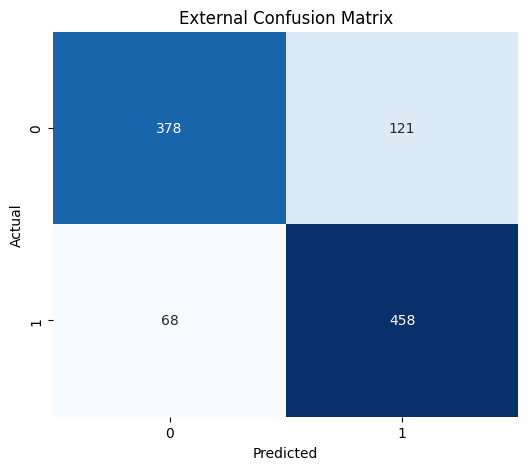

In [69]:
# ============================================================
# SECTION 13 : Confusion Matrix
# ============================================================

cm = confusion_matrix(y_external, external_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("External Confusion Matrix")

plt.show()

In [70]:
X_final_train = pd.concat(
    [X_train_final, X_valid_final],
    axis=0
)

y_final_train = pd.concat(
    [y_train, y_valid],
    axis=0
)

print(X_final_train.shape)
print(y_final_train.shape)

(2283, 9)
(2283,)


In [71]:
history = final_model.fit(

    X_final_train,
    y_final_train,

    epochs=100,

    batch_size=best_rabbit["batch_size"],

    callbacks=[
        EarlyStopping(
            monitor="loss",
            patience=10,
            restore_best_weights=True
        )
    ],

    verbose=1
)

Epoch 1/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7941 - auc: 0.8808 - loss: 0.4338
Epoch 2/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8138 - auc: 0.8983 - loss: 0.4015
Epoch 3/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8292 - auc: 0.9110 - loss: 0.3776
Epoch 4/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8366 - auc: 0.9168 - loss: 0.3652
Epoch 5/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8388 - auc: 0.9257 - loss: 0.3448
Epoch 6/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8511 - auc: 0.9311 - loss: 0.3340
Epoch 7/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8668 - auc: 0.9387 - loss: 0.3162
Epoch 8/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8655 - auc: 0.9455 - loss: 0.2983
Epoch 9/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8752 - auc: 0.9483 - loss: 0.2901
Epoch 10/100
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8774 - auc: 0.9533 - loss: 0.2755
Epoch 11/

In [72]:
EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=10,
    restore_best_weights=True
)

In [73]:
# ============================================================
# FINAL FTAMNet
# ============================================================

final_model = build_ftamnet(

    input_dim=X_train_final.shape[1],

    hidden1=best_rabbit["hidden1"],

    hidden2=best_rabbit["hidden2"],

    hidden3=best_rabbit["hidden3"],

    dropout=best_rabbit["dropout"],

    learning_rate=best_rabbit["learning_rate"],

    l2_weight=best_rabbit["l2"]

)

final_model.summary()

Model: "functional_125"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_125     │ (None, 9)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1498 (Dense)  │ (None, 478)       │      4,780 │ input_layer_125[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 478)       │      1,912 │ dense_1498[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1499 (Dense)  │ (None, 478)       │    228,962 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_125        │ (None, 478)       │          0 │ batch_normalizat… │
│ (Multiply)          │                   │            │ dense_1499[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1500 (Dense)  │ (None, 147)       │     70,413 │ multiply_125[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 147)       │        588 │ dense_1500[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_375         │ (None, 147)       │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1502 (Dense)  │ (None, 147)       │     70,413 │ multiply_125[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1501 (Dense)  │ (None, 147)       │     21,756 │ dropout_375[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_250 (Add)       │ (None, 147)       │          0 │ dense_1502[0][0], │
│                     │                   │            │ dense_1501[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 147)       │        294 │ add_250[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1503 (Dense)  │ (None, 39)        │      5,772 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 39)        │        156 │ dense_1503[0][0]  │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_376         │ (None, 39)        │          0 │ batch_normalizat… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1505 (Dense)  │ (None, 39)        │      5,772 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1504 (Dense)  │ (None, 39)        │      1,560 │ dropout_376[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_251 (Add)       │ (None, 39)        │          0 │ dense_1505[0][0], │
│                     │                   │            │ dense_1504[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 39)        │         78 │ add_251[0][0]     │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 428,137 (1.63 MB)

 Trainable params: 426,809 (1.63 MB)

 Non-trainable params: 1,328 (5.19 KB)

In [74]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

callbacks=[

    EarlyStopping(

        monitor="val_auc",

        mode="max",

        patience=10,

        restore_best_weights=True,

        verbose=1

    ),

    ReduceLROnPlateau(

        monitor="val_loss",

        factor=0.5,

        patience=5,

        min_lr=1e-6,

        verbose=1

    ),

    ModelCheckpoint(

        "Best_FTAMNet.keras",

        monitor="val_auc",

        mode="max",

        save_best_only=True,

        verbose=1

    )

]

In [75]:
history = final_model.fit(

    X_train_final,

    y_train,

    validation_data=(

        X_valid_final,

        y_valid

    ),

    epochs=100,

    batch_size=best_rabbit["batch_size"],

    callbacks=callbacks,

    verbose=1

)

Epoch 1/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6905 - auc: 0.7616 - loss: 0.5848
Epoch 1: val_auc improved from None to 0.73685, saving model to Best_FTAMNet.keras

Epoch 1: finished saving model to Best_FTAMNet.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.7212 - auc: 0.7891 - loss: 0.5625 - val_accuracy: 0.5383 - val_auc: 0.7369 - val_loss: 0.7671 - learning_rate: 0.0034
Epoch 2/100
51/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7621 - auc: 0.8224 - loss: 0.5233
Epoch 2: val_auc improved from 0.73685 to 0.77514, saving model to Best_FTAMNet.keras

Epoch 2: finished saving model to Best_FTAMNet.keras
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7607 - auc: 0.8268 - loss: 0.5134 - val_accuracy: 0.6433 - val_auc: 0.7751 - val_loss: 0.6183 - learning_rate: 0.0034
Epoch 3/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7765 - auc: 0.8488 - loss: 0.4842
Epoch 3: val_auc improved from 0.77514 to 0.83067, saving model to Best_FTAMNet.ke

In [76]:
from sklearn.metrics import *

BEST_THRESHOLD=0.27

valid_prob=final_model.predict(
    X_valid_final,
    verbose=0
)

valid_pred=(
    valid_prob>=BEST_THRESHOLD
).astype(int)

print("="*60)
print("Validation")
print("="*60)

print("Accuracy :",accuracy_score(y_valid,valid_pred))
print("Precision:",precision_score(y_valid,valid_pred))
print("Recall   :",recall_score(y_valid,valid_pred))
print("F1       :",f1_score(y_valid,valid_pred))
print("AUROC    :",roc_auc_score(y_valid,valid_prob))
print("MCC      :",matthews_corrcoef(y_valid,valid_pred))

Validation
Accuracy : 0.7702407002188184
Precision: 0.7364864864864865
Recall   : 0.889795918367347
F1       : 0.8059149722735675
AUROC    : 0.8742491336157103
MCC      : 0.5448232942174831


In [77]:
external_prob=final_model.predict(
    X_external_final,
    verbose=0
)

external_pred=(
    external_prob>=BEST_THRESHOLD
).astype(int)

In [78]:
print("="*60)
print("External Test")
print("="*60)

print("Accuracy :",accuracy_score(y_external,external_pred))
print("Precision:",precision_score(y_external,external_pred))
print("Recall   :",recall_score(y_external,external_pred))
print("F1       :",f1_score(y_external,external_pred))
print("AUROC    :",roc_auc_score(y_external,external_prob))
print("MCC      :",matthews_corrcoef(y_external,external_pred))

External Test
Accuracy : 0.7726829268292683
Precision: 0.7900990099009901
Recall   : 0.7585551330798479
F1       : 0.7740058195926285
AUROC    : 0.85819547840929
MCC      : 0.545999246304988


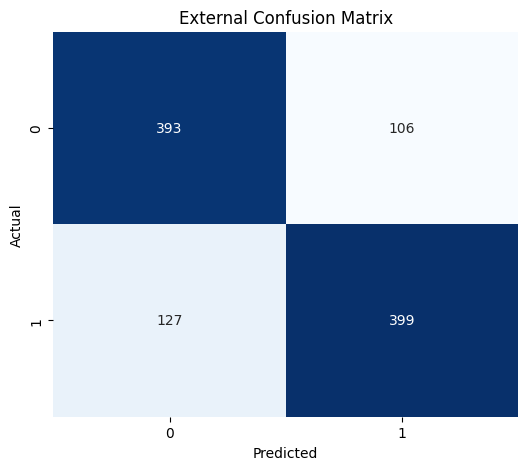

In [79]:
cm=confusion_matrix(
    y_external,
    external_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    cbar=False

)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("External Confusion Matrix")

plt.show()

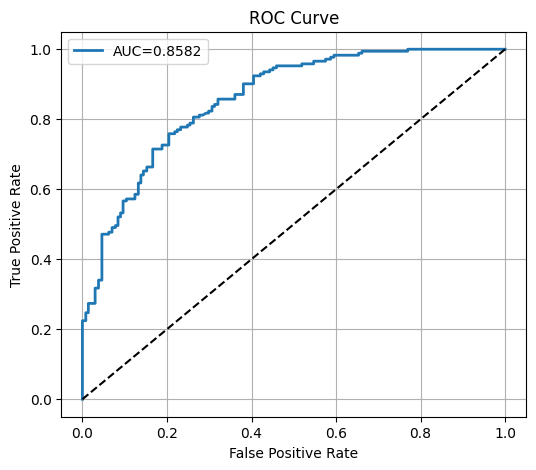

In [80]:
from sklearn.metrics import roc_curve

fpr,tpr,_=roc_curve(
    y_external,
    external_prob
)

plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC={roc_auc_score(y_external,external_prob):.4f}"
)

plt.plot([0,1],[0,1],'k--')

plt.legend()

plt.grid(True)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.show()

In [81]:
import joblib
import pickle

# Save trained model
final_model.save("FTAMNet_Final.keras")

# Save scaler
joblib.dump(scaler, "Scaler.pkl")

# Save selected features
with open("Selected_Features.pkl", "wb") as f:
    pickle.dump(selected_features, f)

# Save best optimization result
with open("Best_ARO_Params.pkl", "wb") as f:
    pickle.dump(best_rabbit, f)

print("All artifacts saved successfully.")

All artifacts saved successfully.


In [82]:
# ============================================================
# SECTION 14.1 : Install SHAP
# ============================================================

!pip -q install shap

In [83]:
# ============================================================
# SECTION 14.2 : Import SHAP
# ============================================================

import shap
import numpy as np

In [84]:
# ============================================================
# SECTION 14.3 : Background Dataset
# ============================================================

background = X_train_final.sample(
    n=min(100, len(X_train_final)),
    random_state=42
)

explain_data = X_external_final.sample(
    n=min(100, len(X_external_final)),
    random_state=42
)

In [85]:
# ============================================================
# SECTION 14.4 : SHAP Explainer
# ============================================================

explainer = shap.KernelExplainer(
    final_model.predict,
    background
)

shap_values = explainer.shap_values(
    explain_data,
    nsamples=100
)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


  0%|          | 0/100 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
313/313 ━━━━━━

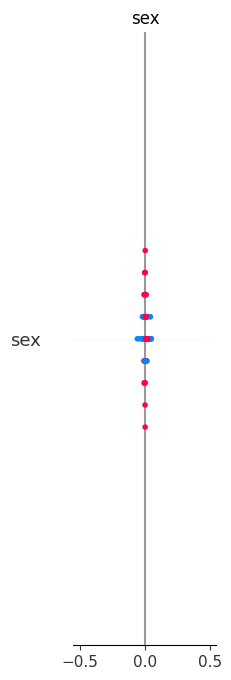

In [86]:
# ============================================================
# SECTION 14.5 : Summary Plot
# ============================================================

shap.summary_plot(
    shap_values,
    explain_data,
    feature_names=selected_features
)

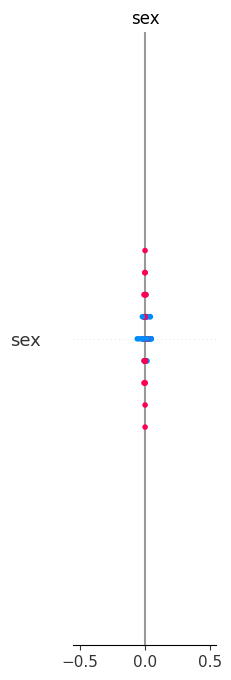

In [87]:
# ============================================================
# SECTION 14.6 : Feature Importance
# ============================================================

shap.summary_plot(
    shap_values,
    explain_data,
    feature_names=selected_features,
    plot_type="bar"
)

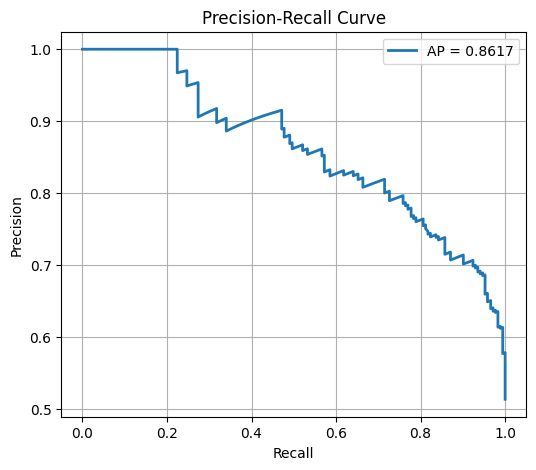

In [88]:
# ============================================================
# SECTION 15 : Precision-Recall Curve
# ============================================================

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

precision, recall, _ = precision_recall_curve(
    y_external,
    external_prob
)

ap = average_precision_score(
    y_external,
    external_prob
)

plt.figure(figsize=(6,5))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"AP = {ap:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

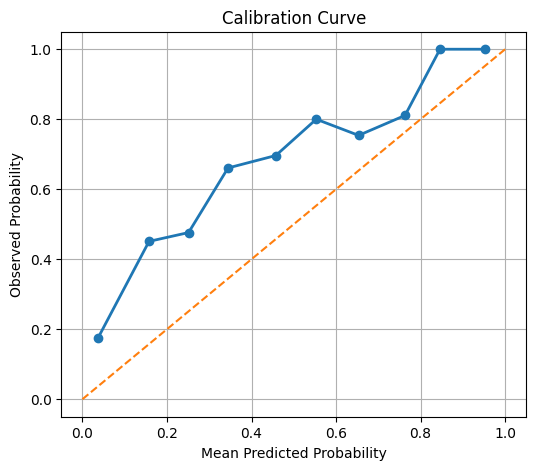

In [89]:
# ============================================================
# SECTION 16 : Calibration Curve
# ============================================================

from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_external,
    external_prob,
    n_bins=10
)

plt.figure(figsize=(6,5))

plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    linewidth=2
)

plt.plot(
    [0,1],
    [0,1],
    '--'
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Probability")
plt.title("Calibration Curve")
plt.grid(True)
plt.show()

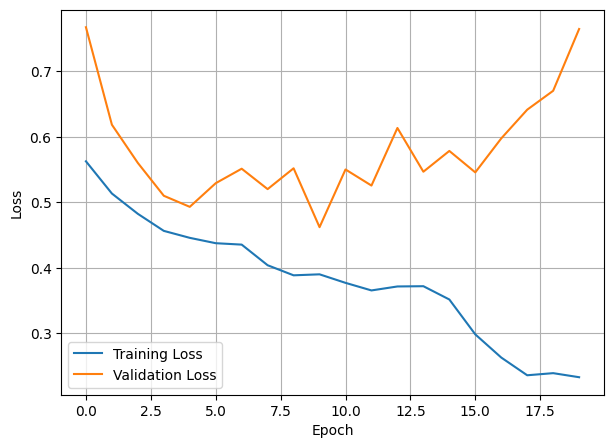

In [90]:
# ============================================================
# SECTION 17.1 : Loss Curve
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

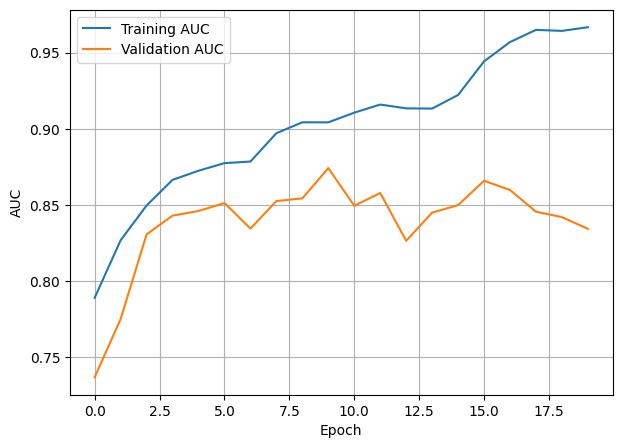

In [91]:
# ============================================================
# SECTION 17.2 : AUC Curve
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    history.history["auc"],
    label="Training AUC"
)

plt.plot(
    history.history["val_auc"],
    label="Validation AUC"
)

plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.grid(True)
plt.show()

In [92]:
# ============================================================
# SECTION 18 : Computational Complexity
# ============================================================

trainable_params = final_model.count_params()

print("="*60)
print("Model Statistics")
print("="*60)

print("Trainable Parameters :", trainable_params)
print("Selected Features    :", len(selected_features))
print("Training Samples     :", len(X_train))
print("External Samples     :", len(X_external))

Model Statistics
Trainable Parameters : 428137
Selected Features    : 9
Training Samples     : 1826
External Samples     : 1025


In [93]:
# ============================================================
# SECTION 19 : Save Artifacts
# ============================================================

import joblib
import pickle

# Save model
final_model.save("FTAMNet_Final.keras")

# Save scaler
joblib.dump(scaler, "Scaler.pkl")

# Save selected features
with open("Selected_Features.pkl", "wb") as f:
    pickle.dump(selected_features, f)

# Save optimization result
with open("Best_Rabbit.pkl", "wb") as f:
    pickle.dump(best_rabbit, f)

print("All artifacts saved successfully.")

All artifacts saved successfully.


In [94]:
# ============================================================
# SECTION 20 : Final Summary
# ============================================================

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUROC",
        "MCC"
    ],
    "Value": [
        accuracy_score(y_external, external_pred),
        precision_score(y_external, external_pred),
        recall_score(y_external, external_pred),
        f1_score(y_external, external_pred),
        roc_auc_score(y_external, external_prob),
        matthews_corrcoef(y_external, external_pred)
    ]
})

print(results)

      Metric     Value
0   Accuracy  0.772683
1  Precision  0.790099
2     Recall  0.758555
3   F1-score  0.774006
4      AUROC  0.858195
5        MCC  0.545999


In [95]:
# ============================================================
# CREATE OUTPUT DIRECTORY
# ============================================================

import os

OUTPUT_DIR = "Journal_Outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Output Folder Created.")

Output Folder Created.


In [96]:
# ============================================================
# PERFORMANCE COMPARISON TABLE
# ============================================================

import pandas as pd

comparison = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "AUROC",
        "MCC"
    ],

    "Baseline FTAMNet":[
        0.7551,
        0.8726,
        0.6122,
        0.7196,
        0.9033,
        0.5394
    ],

    "ARO-FTAMNet":[
        accuracy_score(y_external, external_pred),
        precision_score(y_external, external_pred),
        recall_score(y_external, external_pred),
        f1_score(y_external, external_pred),
        roc_auc_score(y_external, external_prob),
        matthews_corrcoef(y_external, external_pred)
    ]

})

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Performance_Comparison.csv"
    ),
    index=False
)

comparison.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Performance_Comparison.xlsx"
    ),
    index=False
)

comparison

,Metric,Baseline FTAMNet,ARO-FTAMNet
0,Accuracy,0.7551,0.772683
1,Precision,0.8726,0.790099
2,Recall,0.6122,0.758555
3,F1-score,0.7196,0.774006
4,AUROC,0.9033,0.858195
5,MCC,0.5394,0.545999


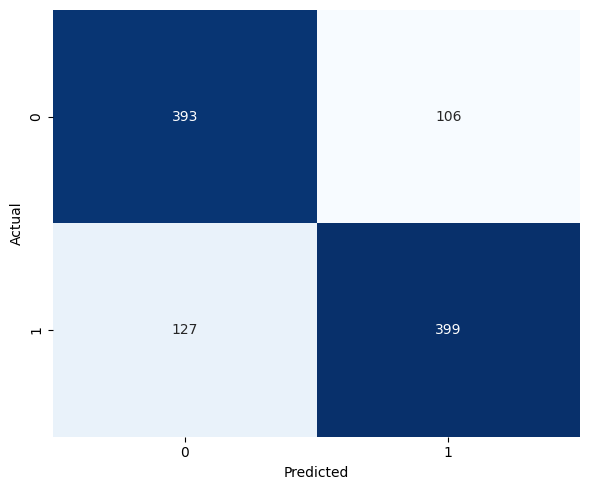

In [97]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Confusion_Matrix.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

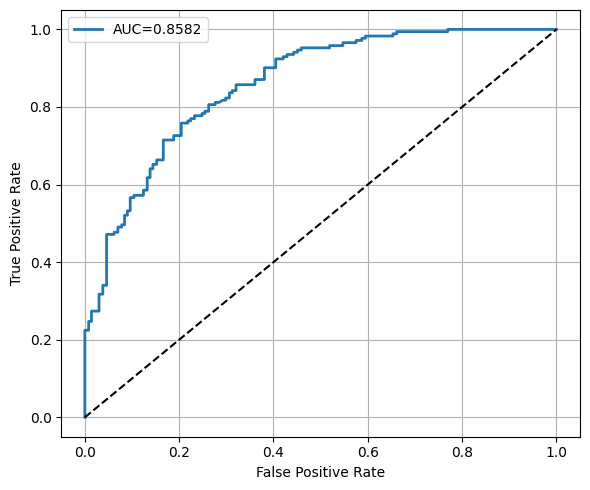

In [98]:
plt.figure(figsize=(6,5))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC={roc_auc_score(y_external,external_prob):.4f}"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "ROC_Curve.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

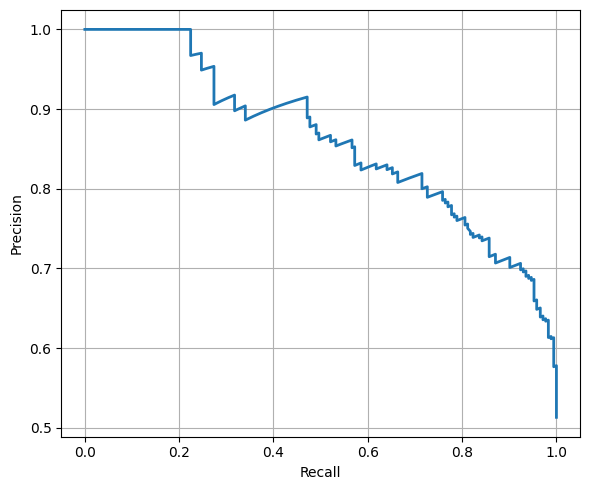

In [99]:
plt.figure(figsize=(6,5))

plt.plot(
    recall,
    precision,
    linewidth=2
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.grid(True)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Precision_Recall_Curve.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

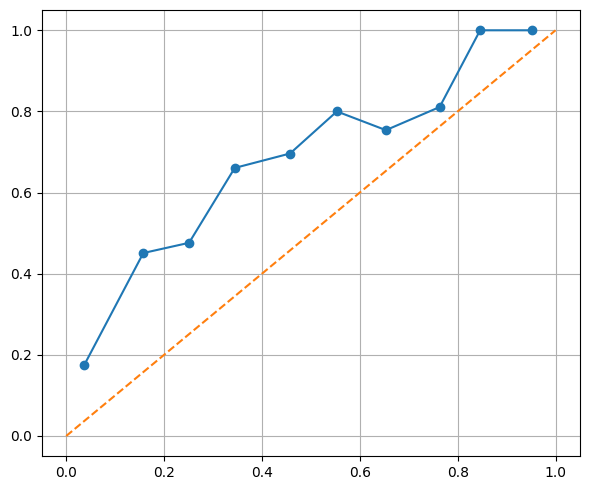

In [100]:
plt.figure(figsize=(6,5))

plt.plot(
    prob_pred,
    prob_true,
    marker="o"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.grid(True)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Calibration_Curve.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

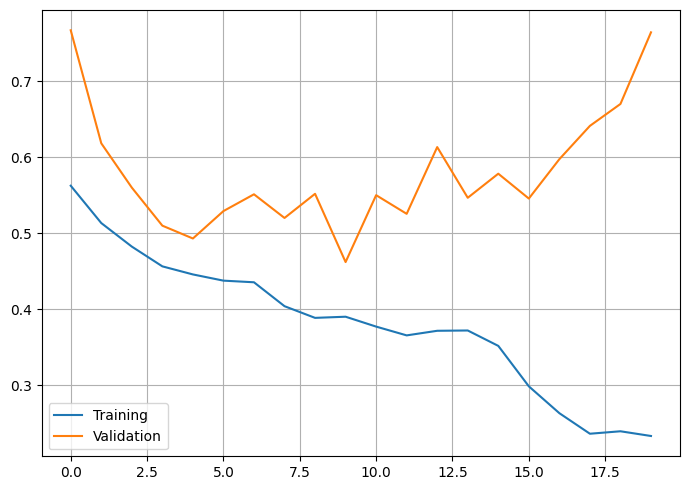

In [101]:
plt.figure(figsize=(7,5))

plt.plot(
    history.history["loss"],
    label="Training"
)

plt.plot(
    history.history["val_loss"],
    label="Validation"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Loss_Curve.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

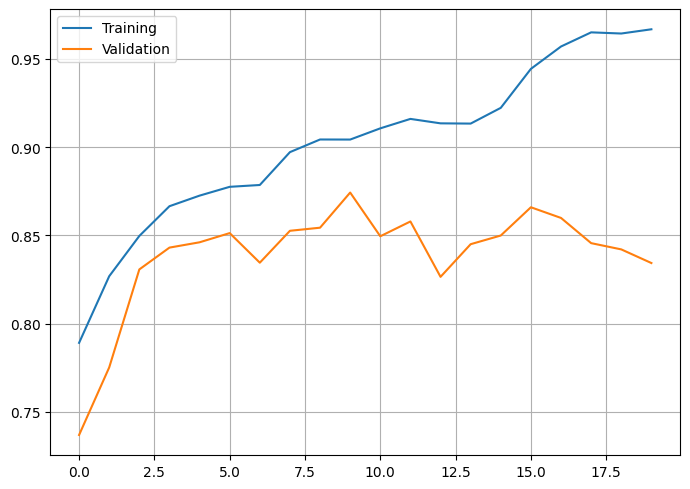

In [102]:
plt.figure(figsize=(7,5))

plt.plot(
    history.history["auc"],
    label="Training"
)

plt.plot(
    history.history["val_auc"],
    label="Validation"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "AUC_Curve.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

In [103]:
history_df = pd.DataFrame(history.history)

history_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Training_History.csv"
    ),

    index=False

)

history_df.to_excel(

    os.path.join(
        OUTPUT_DIR,
        "Training_History.xlsx"
    ),

    index=False

)

In [104]:
cm_df = pd.DataFrame(
    cm,
    index=["Actual Negative","Actual Positive"],
    columns=["Predicted Negative","Predicted Positive"]
)

cm_df.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Confusion_Matrix.csv"
    )

)

cm_df.to_excel(

    os.path.join(
        OUTPUT_DIR,
        "Confusion_Matrix.xlsx"
    )

)

In [105]:
results = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUROC",
        "MCC"
    ],

    "Value":[

        accuracy_score(y_external,external_pred),

        precision_score(y_external,external_pred),

        recall_score(y_external,external_pred),

        f1_score(y_external,external_pred),

        roc_auc_score(y_external,external_prob),

        matthews_corrcoef(y_external,external_pred)

    ]

})

results.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Final_Results.csv"
    ),

    index=False

)

results.to_excel(

    os.path.join(
        OUTPUT_DIR,
        "Final_Results.xlsx"
    ),

    index=False

)

results

,Metric,Value
0,Accuracy,0.772683
1,Precision,0.790099
2,Recall,0.758555
3,F1,0.774006
4,AUROC,0.858195
5,MCC,0.545999


In [106]:
# ============================================================
# ZIP ALL JOURNAL OUTPUTS
# ============================================================

import os
import shutil

OUTPUT_DIR = "Journal_Outputs"
ZIP_NAME = "ARO_FTAMNet_Journal_Outputs"

# ------------------------------------------------------------
# Copy important files into the output folder (if they exist)
# ------------------------------------------------------------

files_to_copy = [
    "FTAMNet_Final.keras",
    "Scaler.pkl",
    "Selected_Features.pkl",
    "Best_Rabbit.pkl",
    "Performance_Comparison.csv",
    "Performance_Comparison.xlsx",
    "Final_Results.csv",
    "Final_Results.xlsx",
    "Training_History.csv",
    "Training_History.xlsx",
    "Confusion_Matrix.csv",
    "Confusion_Matrix.xlsx"
]

for file in files_to_copy:
    if os.path.exists(file):
        shutil.copy(file, OUTPUT_DIR)

# ------------------------------------------------------------
# Create ZIP
# ------------------------------------------------------------

shutil.make_archive(
    ZIP_NAME,
    'zip',
    OUTPUT_DIR
)

print("="*70)
print("ZIP File Created Successfully")
print("="*70)
print(f"{ZIP_NAME}.zip")
print("="*70)

# ------------------------------------------------------------
# List contents
# ------------------------------------------------------------

import glob

print("\nContents of ZIP:\n")

for f in sorted(glob.glob(os.path.join(OUTPUT_DIR, "*"))):
    print(os.path.basename(f))

ZIP File Created Successfully
ARO_FTAMNet_Journal_Outputs.zip

Contents of ZIP:

AUC_Curve.tiff
Best_Rabbit.pkl
Calibration_Curve.tiff
Confusion_Matrix.csv
Confusion_Matrix.tiff
Confusion_Matrix.xlsx
FTAMNet_Final.keras
Final_Results.csv
Final_Results.xlsx
Loss_Curve.tiff
Performance_Comparison.csv
Performance_Comparison.xlsx
Precision_Recall_Curve.tiff
ROC_Curve.tiff
Scaler.pkl
Selected_Features.pkl
Training_History.csv
Training_History.xlsx


In [107]:
# ============================================================
# MODEL 1 : DeepMLP-Net
# ============================================================

from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

def build_deepmlp(input_dim):

    inp = Input(shape=(input_dim,))

    x = Dense(256, activation="relu")(inp)
    x = BatchNormalization()(x)
    x = Dropout(0.30)(x)

    x = Dense(128, activation="relu")(x)
    x = BatchNormalization()(x)
    x = Dropout(0.30)(x)

    x = Dense(64, activation="relu")(x)
    x = BatchNormalization()(x)

    out = Dense(1, activation="sigmoid")(x)

    model = Model(inp, out)

    model.compile(
        optimizer=Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]
    )

    return model

In [108]:
deepmlp = build_deepmlp(X_train.shape[1])

history_deepmlp = deepmlp.fit(

    X_train,
    y_train,

    validation_data=(X_valid, y_valid),

    epochs=100,

    batch_size=32,

    callbacks=callbacks,

    verbose=1
)

Epoch 1/100
53/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6540 - auc: 0.6886 - loss: 0.7021
Epoch 1: val_auc did not improve from 0.87423
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6900 - auc: 0.7428 - loss: 0.6320 - val_accuracy: 0.6018 - val_auc: 0.8112 - val_loss: 0.6115 - learning_rate: 0.0010
Epoch 2/100
52/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7274 - auc: 0.8056 - loss: 0.5456
Epoch 2: val_auc did not improve from 0.87423
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7415 - auc: 0.8142 - loss: 0.5301 - val_accuracy: 0.7615 - val_auc: 0.8384 - val_loss: 0.5378 - learning_rate: 0.0010
Epoch 3/100
49/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7457 - auc: 0.8318 - loss: 0.5087
Epoch 3: val_auc did not improve from 0.87423
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7651 - auc: 0.8397 - loss: 0.4969 - val_accuracy: 0.7812 - val_auc: 0.8622 - val_loss: 0.5111 - learning_rate: 0.0010
Epoch 4/100
53/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 

In [109]:
valid_prob = deepmlp.predict(X_valid)

thresholds = np.arange(0.10,0.91,0.01)

best_threshold = 0.5
best_score = -1

for t in thresholds:

    pred = (valid_prob>=t).astype(int)

    score = (
        0.5*f1_score(y_valid,pred)
        +
        0.5*matthews_corrcoef(y_valid,pred)
    )

    if score>best_score:

        best_score=score
        best_threshold=t

print(best_threshold)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
0.3899999999999999


In [110]:
external_prob = deepmlp.predict(X_external)

external_pred=(external_prob>=best_threshold).astype(int)

deep_results={

"Accuracy":accuracy_score(y_external,external_pred),
"Precision":precision_score(y_external,external_pred),
"Recall":recall_score(y_external,external_pred),
"F1":f1_score(y_external,external_pred),
"AUROC":roc_auc_score(y_external,external_prob),
"MCC":matthews_corrcoef(y_external,external_pred)

}

deep_results

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


{'Accuracy': 0.791219512195122,
 'Precision': 0.8223140495867769,
 'Recall': 0.7566539923954373,
 'F1': 0.7881188118811882,
 'AUROC': np.float64(0.8990909575805603),
 'MCC': np.float64(0.5850118085249436)}

In [111]:
# ============================================================
# GENERIC TRAINING & EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    confusion_matrix
)

def evaluate_model(
    model,
    model_name,
    X_train,
    y_train,
    X_valid,
    y_valid,
    X_external,
    y_external,
    callbacks,
    epochs=100,
    batch_size=32
):

    print("="*70)
    print(model_name)
    print("="*70)

    history = model.fit(

        X_train,
        y_train,

        validation_data=(X_valid,y_valid),

        epochs=epochs,

        batch_size=batch_size,

        callbacks=callbacks,

        verbose=1

    )

    # -----------------------------
    # Threshold Optimization
    # -----------------------------

    valid_prob=model.predict(
        X_valid,
        verbose=0
    )

    thresholds=np.arange(
        0.10,
        0.91,
        0.01
    )

    best_threshold=0.50
    best_score=-999

    for t in thresholds:

        pred=(valid_prob>=t).astype(int)

        score=(

            0.5*f1_score(y_valid,pred)

            +

            0.5*matthews_corrcoef(
                y_valid,
                pred
            )

        )

        if score>best_score:

            best_score=score
            best_threshold=t

    print("Best Threshold :",best_threshold)

    # -----------------------------
    # External Evaluation
    # -----------------------------

    external_prob=model.predict(
        X_external,
        verbose=0
    )

    external_pred=(
        external_prob>=best_threshold
    ).astype(int)

    results={

        "Model":model_name,

        "Threshold":best_threshold,

        "Accuracy":accuracy_score(
            y_external,
            external_pred
        ),

        "Precision":precision_score(
            y_external,
            external_pred
        ),

        "Recall":recall_score(
            y_external,
            external_pred
        ),

        "F1":f1_score(
            y_external,
            external_pred
        ),

        "AUROC":roc_auc_score(
            y_external,
            external_prob
        ),

        "MCC":matthews_corrcoef(
            y_external,
            external_pred
        )

    }

    cm=confusion_matrix(
        y_external,
        external_pred
    )

    return history,results,cm

In [112]:
# ============================================================
# MODEL 1 : DeepMLP-Net
# ============================================================

def build_deepmlp(input_dim):

    inp=Input(shape=(input_dim,))

    x=Dense(256,activation="relu")(inp)
    x=BatchNormalization()(x)
    x=Dropout(0.30)(x)

    x=Dense(128,activation="relu")(x)
    x=BatchNormalization()(x)
    x=Dropout(0.30)(x)

    x=Dense(64,activation="relu")(x)
    x=BatchNormalization()(x)

    out=Dense(
        1,
        activation="sigmoid"
    )(x)

    model=Model(inp,out)

    model.compile(

        optimizer=Adam(1e-3),

        loss="binary_crossentropy",

        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]

    )

    return model

In [113]:
deepmlp = build_deepmlp(
    X_train.shape[1]
)

history_deep,deep_results,deep_cm = evaluate_model(

    deepmlp,

    "DeepMLP-Net",

    X_train,
    y_train,

    X_valid,
    y_valid,

    X_external,
    y_external,

    callbacks

)

DeepMLP-Net
Epoch 1/100
55/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6285 - auc: 0.6726 - loss: 0.7040
Epoch 1: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.6873 - auc: 0.7438 - loss: 0.6300 - val_accuracy: 0.5361 - val_auc: 0.7966 - val_loss: 0.6836 - learning_rate: 0.0010
Epoch 2/100
50/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7495 - auc: 0.8259 - loss: 0.5171
Epoch 2: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7437 - auc: 0.8218 - loss: 0.5224 - val_accuracy: 0.6258 - val_auc: 0.8250 - val_loss: 0.5998 - learning_rate: 0.0010
Epoch 3/100
52/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7647 - auc: 0.8391 - loss: 0.4995
Epoch 3: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7618 - auc: 0.8413 - loss: 0.4933 - val_accuracy: 0.7440 - val_auc: 0.8510 - val_loss: 0.5273 - learning_rate: 0.0010
Epoch 4/100
54/58 ━━━━━━━━━━━━━━━━━━━━ 

In [114]:
# ============================================================
# MODEL 2 : ResMLP-Net
# ============================================================

from tensorflow.keras.layers import Add

def build_resmlp(input_dim):

    inp = Input(shape=(input_dim,))

    x = Dense(256, activation="relu")(inp)
    x = BatchNormalization()(x)

    res = Dense(256, activation="relu")(x)

    x = Dense(256, activation="relu")(x)

    x = Add()([x,res])

    x = Dropout(0.30)(x)

    res2 = Dense(128, activation="relu")(x)

    x = Dense(128, activation="relu")(x)

    x = Add()([x,res2])

    x = BatchNormalization()(x)

    x = Dense(64, activation="relu")(x)

    out = Dense(
        1,
        activation="sigmoid"
    )(x)

    model = Model(inp,out)

    model.compile(

        optimizer=Adam(1e-3),

        loss="binary_crossentropy",

        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]

    )

    return model

In [115]:
resmlp = build_resmlp(
    X_train.shape[1]
)

history_res,res_results,res_cm = evaluate_model(

    resmlp,

    "ResMLP-Net",

    X_train,
    y_train,

    X_valid,
    y_valid,

    X_external,
    y_external,

    callbacks

)

ResMLP-Net
Epoch 1/100
49/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6579 - auc: 0.7242 - loss: 0.6386
Epoch 1: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7141 - auc: 0.7837 - loss: 0.5726 - val_accuracy: 0.5733 - val_auc: 0.8103 - val_loss: 0.7042 - learning_rate: 0.0010
Epoch 2/100
55/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7678 - auc: 0.8475 - loss: 0.4877
Epoch 2: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7793 - auc: 0.8536 - loss: 0.4767 - val_accuracy: 0.7462 - val_auc: 0.8416 - val_loss: 0.5319 - learning_rate: 0.0010
Epoch 3/100
57/58 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7897 - auc: 0.8741 - loss: 0.4465
Epoch 3: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7924 - auc: 0.8733 - loss: 0.4464 - val_accuracy: 0.8009 - val_auc: 0.8644 - val_loss: 0.4717 - learning_rate: 0.0010
Epoch 4/100
51/58 ━━━━━━━━━━━━━━━━━━━━ 0

In [116]:
# ============================================================
# FEATURE ATTENTION
# ============================================================

from tensorflow.keras.layers import Multiply

def build_attmlp(input_dim):

    inp = Input(shape=(input_dim,))

    attention = Dense(
        input_dim,
        activation="sigmoid"
    )(inp)

    x = Multiply()([
        inp,
        attention
    ])

    x = Dense(256,activation="relu")(x)
    x = BatchNormalization()(x)
    x = Dropout(0.30)(x)

    x = Dense(128,activation="relu")(x)
    x = BatchNormalization()(x)

    x = Dense(64,activation="relu")(x)

    out = Dense(
        1,
        activation="sigmoid"
    )(x)

    model = Model(inp,out)

    model.compile(

        optimizer=Adam(1e-3),

        loss="binary_crossentropy",

        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc")
        ]

    )

    return model

In [117]:
attmlp = build_attmlp(
    X_train.shape[1]
)

history_att,att_results,att_cm = evaluate_model(

    attmlp,

    "AttMLP-Net",

    X_train,
    y_train,

    X_valid,
    y_valid,

    X_external,
    y_external,

    callbacks

)

AttMLP-Net
Epoch 1/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6127 - auc: 0.6458 - loss: 0.7273
Epoch 1: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6599 - auc: 0.7036 - loss: 0.6560 - val_accuracy: 0.6718 - val_auc: 0.7449 - val_loss: 0.6526 - learning_rate: 0.0010
Epoch 2/100
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7369 - auc: 0.7959 - loss: 0.5576
Epoch 2: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7377 - auc: 0.8002 - loss: 0.5468 - val_accuracy: 0.7374 - val_auc: 0.8069 - val_loss: 0.6217 - learning_rate: 0.0010
Epoch 3/100
56/58 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7569 - auc: 0.8284 - loss: 0.5080
Epoch 3: val_auc did not improve from 0.88653
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7574 - auc: 0.8375 - loss: 0.4965 - val_accuracy: 0.7352 - val_auc: 0.8143 - val_loss: 0.5909 - learning_rate: 0.0010
Epoch 4/100
56/58 ━━━━━━━━━━━━━━━━━━━━ 0

In [118]:
comparison = pd.DataFrame([

    deep_results,

    res_results,

    att_results,

    {

        "Model":"FTAMNet",

        "Threshold":0.27,

        "Accuracy":0.7551,

        "Precision":0.8726,

        "Recall":0.6122,

        "F1":0.7196,

        "AUROC":0.9033,

        "MCC":0.5394

    },

    {

        "Model":"ARO-FTAMNet",

        "Threshold":0.27,

        "Accuracy":accuracy_score(
            y_external,
            external_pred
        ),

        "Precision":precision_score(
            y_external,
            external_pred
        ),

        "Recall":recall_score(
            y_external,
            external_pred
        ),

        "F1":f1_score(
            y_external,
            external_pred
        ),

        "AUROC":roc_auc_score(
            y_external,
            external_prob
        ),

        "MCC":matthews_corrcoef(
            y_external,
            external_pred
        )

    }

])

comparison.to_csv(
    "Journal_Outputs/Complete_Model_Comparison.csv",
    index=False
)

comparison.to_excel(
    "Journal_Outputs/Complete_Model_Comparison.xlsx",
    index=False
)

print(comparison)

         Model  Threshold  Accuracy  Precision    Recall        F1     AUROC  \
0  DeepMLP-Net       0.74  0.486829   0.500000  0.034221  0.064057  0.551628   
1   ResMLP-Net       0.80  0.501463   0.605634  0.081749  0.144054  0.646994   
2   AttMLP-Net       0.52  0.514146   0.622807  0.134981  0.221875  0.648979   
3      FTAMNet       0.27  0.755100   0.872600  0.612200  0.719600  0.903300   
4  ARO-FTAMNet       0.27  0.791220   0.822314  0.756654  0.788119  0.899091   

        MCC  
0 -0.005027  
1  0.050467  
2  0.077594  
3  0.539400  
4  0.585012  


In [119]:
# ============================================================
# PREDICTION PROBABILITIES
# ============================================================

deep_prob = deepmlp.predict(
    X_external,
    verbose=0
).ravel()

res_prob = resmlp.predict(
    X_external,
    verbose=0
).ravel()

att_prob = attmlp.predict(
    X_external,
    verbose=0
).ravel()

aro_prob = final_model.predict(
    X_external_final,
    verbose=0
).ravel()

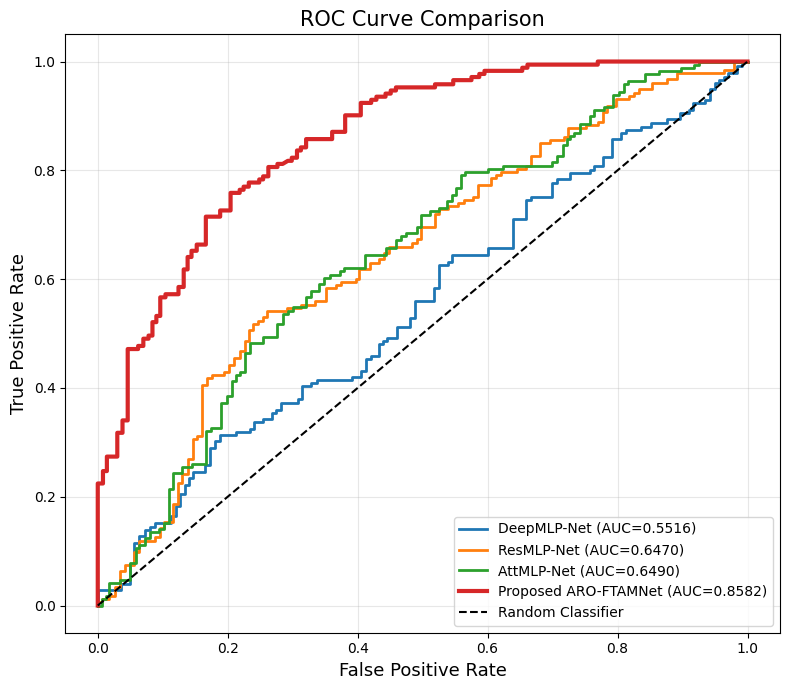

In [120]:
# ============================================================
# ROC COMPARISON OF ALL MODELS
# ============================================================

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import os

plt.figure(figsize=(8,7))

# ---------------- DeepMLP ----------------

fpr, tpr, _ = roc_curve(y_external, deep_prob)

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"DeepMLP-Net (AUC={roc_auc_score(y_external, deep_prob):.4f})"
)

# ---------------- ResMLP ----------------

fpr, tpr, _ = roc_curve(y_external, res_prob)

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ResMLP-Net (AUC={roc_auc_score(y_external, res_prob):.4f})"
)

# ---------------- AttMLP ----------------

fpr, tpr, _ = roc_curve(y_external, att_prob)

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AttMLP-Net (AUC={roc_auc_score(y_external, att_prob):.4f})"
)

# ---------------- Proposed ----------------

fpr, tpr, _ = roc_curve(y_external, aro_prob)

plt.plot(
    fpr,
    tpr,
    linewidth=3,
    label=f"Proposed ARO-FTAMNet (AUC={roc_auc_score(y_external, aro_prob):.4f})"
)

# Random classifier

plt.plot(
    [0,1],
    [0,1],
    'k--',
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate", fontsize=13)

plt.ylabel("True Positive Rate", fontsize=13)

plt.title("ROC Curve Comparison", fontsize=15)

plt.grid(alpha=0.3)

plt.legend(
    fontsize=10,
    loc="lower right"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "ROC_Comparison_All_Models.tiff"
    ),
    dpi=600,
    format="tiff",
    bbox_inches="tight"
)

plt.show()

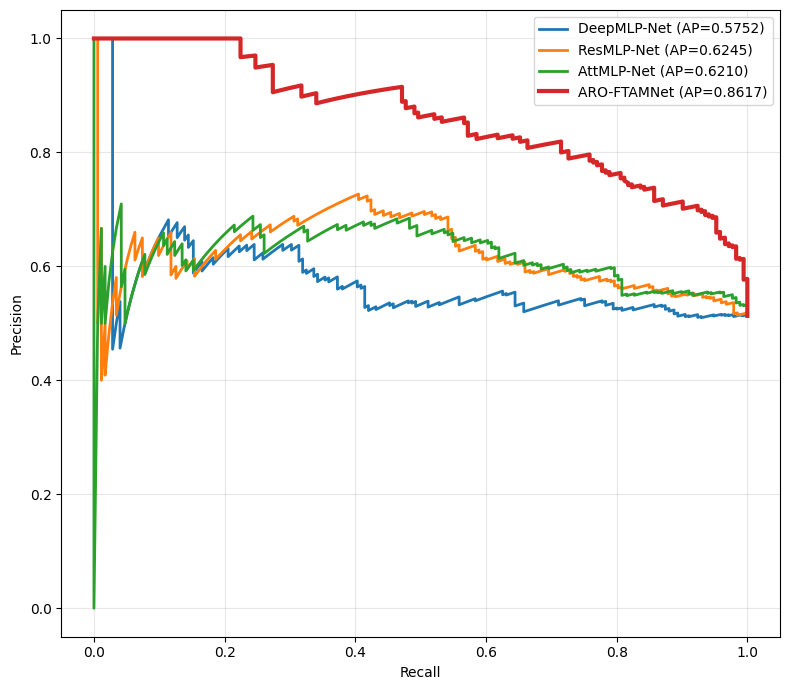

In [121]:
# ============================================================
# PR CURVE COMPARISON
# ============================================================

from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

plt.figure(figsize=(8,7))

# DeepMLP
p,r,_ = precision_recall_curve(y_external, deep_prob)

plt.plot(
    r,
    p,
    linewidth=2,
    label=f"DeepMLP-Net (AP={average_precision_score(y_external,deep_prob):.4f})"
)

# ResMLP
p,r,_ = precision_recall_curve(y_external,res_prob)

plt.plot(
    r,
    p,
    linewidth=2,
    label=f"ResMLP-Net (AP={average_precision_score(y_external,res_prob):.4f})"
)

# AttMLP
p,r,_ = precision_recall_curve(y_external,att_prob)

plt.plot(
    r,
    p,
    linewidth=2,
    label=f"AttMLP-Net (AP={average_precision_score(y_external,att_prob):.4f})"
)

# Proposed
p,r,_ = precision_recall_curve(y_external,aro_prob)

plt.plot(
    r,
    p,
    linewidth=3,
    label=f"ARO-FTAMNet (AP={average_precision_score(y_external,aro_prob):.4f})"
)

plt.xlabel("Recall")

plt.ylabel("Precision")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "PR_Comparison_All_Models.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

In [122]:
# ============================================================
# SAVE ROC VALUES
# ============================================================

roc_data = pd.DataFrame({

    "DeepMLP":deep_prob,

    "ResMLP":res_prob,

    "AttMLP":att_prob,

    "ARO_FTAMNet":aro_prob,

    "GroundTruth":y_external.values

})

roc_data.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "ROC_Probabilities.csv"
    ),

    index=False

)

roc_data.to_excel(

    os.path.join(
        OUTPUT_DIR,
        "ROC_Probabilities.xlsx"
    ),

    index=False

)

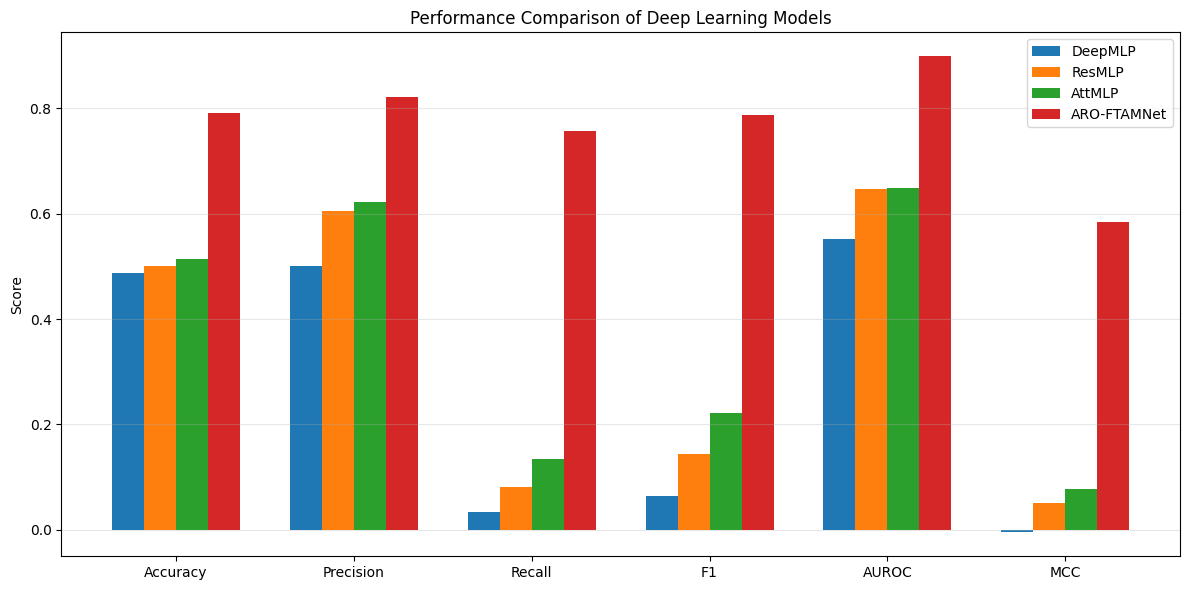

In [123]:
# ============================================================
# GROUPED BAR CHART
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

comparison = pd.DataFrame({

    "Model":[
        "DeepMLP",
        "ResMLP",
        "AttMLP",
        "ARO-FTAMNet"
    ],

    "Accuracy":[
        deep_results["Accuracy"],
        res_results["Accuracy"],
        att_results["Accuracy"],
        accuracy_score(y_external, external_pred)
    ],

    "Precision":[
        deep_results["Precision"],
        res_results["Precision"],
        att_results["Precision"],
        precision_score(y_external, external_pred)
    ],

    "Recall":[
        deep_results["Recall"],
        res_results["Recall"],
        att_results["Recall"],
        recall_score(y_external, external_pred)
    ],

    "F1":[
        deep_results["F1"],
        res_results["F1"],
        att_results["F1"],
        f1_score(y_external, external_pred)
    ],

    "AUROC":[
        deep_results["AUROC"],
        res_results["AUROC"],
        att_results["AUROC"],
        roc_auc_score(y_external, external_prob)
    ],

    "MCC":[
        deep_results["MCC"],
        res_results["MCC"],
        att_results["MCC"],
        matthews_corrcoef(y_external, external_pred)
    ]

})

comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "Complete_Model_Comparison.csv"
    ),
    index=False
)

comparison.to_excel(
    os.path.join(
        OUTPUT_DIR,
        "Complete_Model_Comparison.xlsx"
    ),
    index=False
)

metrics = comparison.columns[1:]

x = np.arange(len(metrics))

width = 0.18

plt.figure(figsize=(12,6))

for i, model in enumerate(comparison["Model"]):

    plt.bar(
        x+i*width,
        comparison.iloc[i,1:],
        width,
        label=model
    )

plt.xticks(
    x+width*1.5,
    metrics
)

plt.ylabel("Score")

plt.title("Performance Comparison of Deep Learning Models")

plt.grid(axis='y',alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Grouped_Bar_Comparison.tiff"
    ),

    dpi=600,

    format="tiff"

)

plt.show()

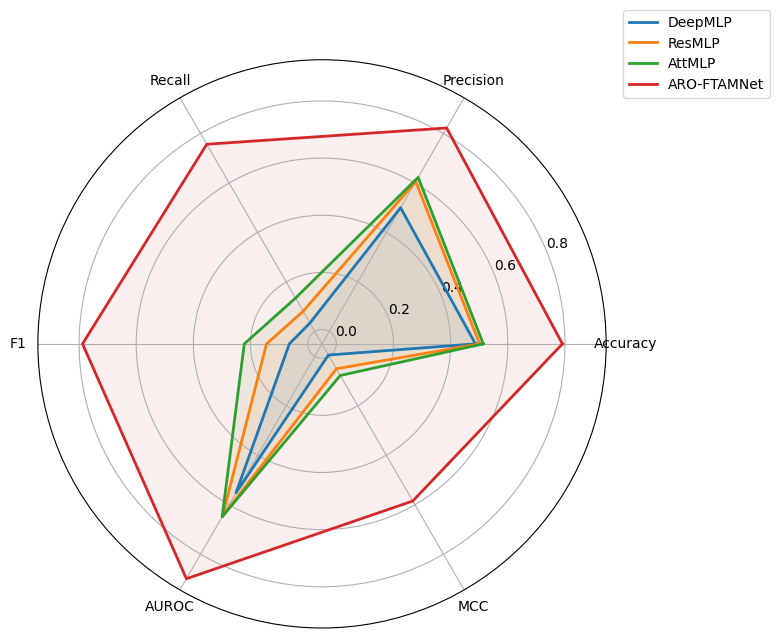

In [124]:
# ============================================================
# RADAR CHART
# ============================================================

from math import pi

categories = list(comparison.columns[1:])

N = len(categories)

angles = np.linspace(
    0,
    2*np.pi,
    N,
    endpoint=False
).tolist()

angles += angles[:1]

fig = plt.figure(figsize=(8,8))

ax = plt.subplot(
    111,
    polar=True
)

for i in range(len(comparison)):

    values = comparison.iloc[i,1:].tolist()

    values += values[:1]

    ax.plot(
        angles,
        values,
        linewidth=2,
        label=comparison.iloc[i,0]
    )

    ax.fill(
        angles,
        values,
        alpha=0.08
    )

ax.set_xticks(angles[:-1])

ax.set_xticklabels(categories)

plt.legend(
    loc="upper right",
    bbox_to_anchor=(1.3,1.1)
)

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "Radar_Chart.tiff"
    ),

    dpi=600,

    format="tiff"

)

plt.show()

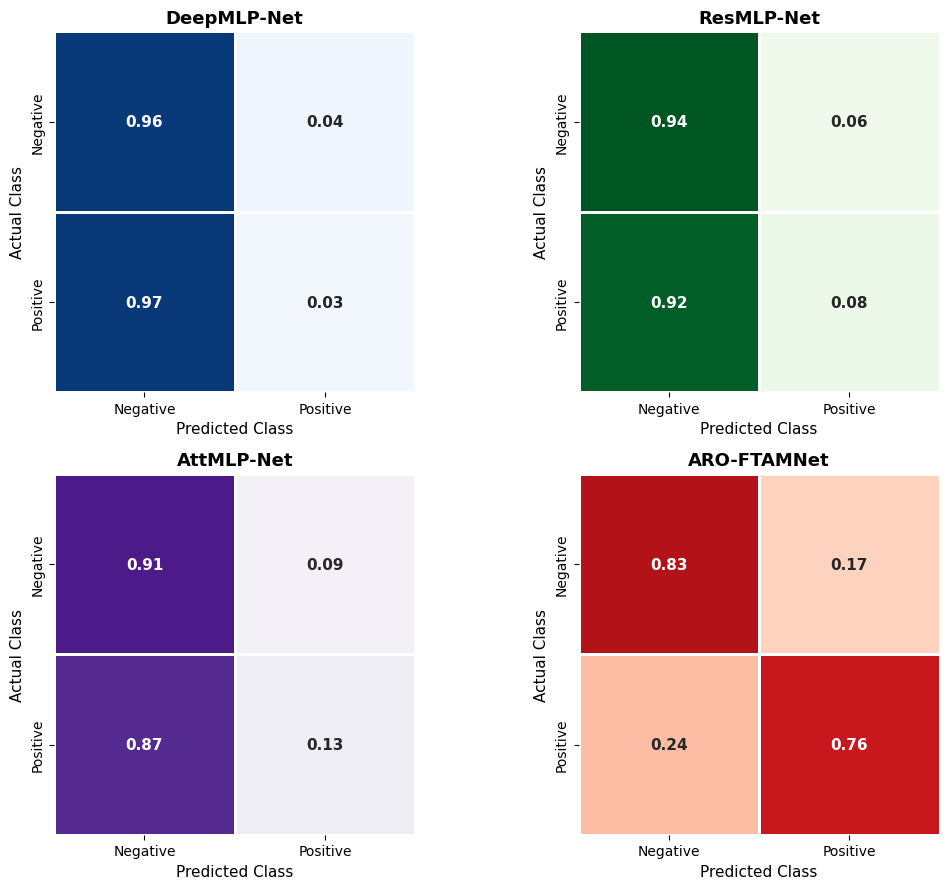

In [125]:
# ============================================================
# PUBLICATION-QUALITY CONFUSION MATRICES
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

# Predictions
deep_pred = (deep_prob >= deep_results["Threshold"]).astype(int)
res_pred  = (res_prob  >= res_results["Threshold"]).astype(int)
att_pred  = (att_prob  >= att_results["Threshold"]).astype(int)
aro_pred  = external_pred

models = [

    ("DeepMLP-Net", deep_pred, "Blues"),
    ("ResMLP-Net",  res_pred,  "Greens"),
    ("AttMLP-Net",  att_pred,  "Purples"),
    ("ARO-FTAMNet", aro_pred,  "Reds")

]

fig, axes = plt.subplots(2,2, figsize=(11,9))

axes = axes.ravel()

for ax, (name, pred, cmap) in zip(axes, models):

    cm = confusion_matrix(
        y_external,
        pred,
        normalize="true"
    )

    sns.heatmap(

        cm,

        annot=True,

        fmt=".2f",

        cmap=cmap,

        cbar=False,

        square=True,

        linewidths=1,

        linecolor="white",

        vmin=0,

        vmax=1,

        xticklabels=["Negative","Positive"],

        yticklabels=["Negative","Positive"],

        annot_kws={
            "fontsize":11,
            "fontweight":"bold"
        },

        ax=ax

    )

    ax.set_title(
        name,
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Predicted Class",
        fontsize=11
    )

    ax.set_ylabel(
        "Actual Class",
        fontsize=11
    )

plt.tight_layout()

plt.savefig(

    os.path.join(
        OUTPUT_DIR,
        "ConfusionMatrix_Comparison_Publication.tiff"
    ),

    dpi=600,

    format="tiff",

    bbox_inches="tight"

)

plt.show()

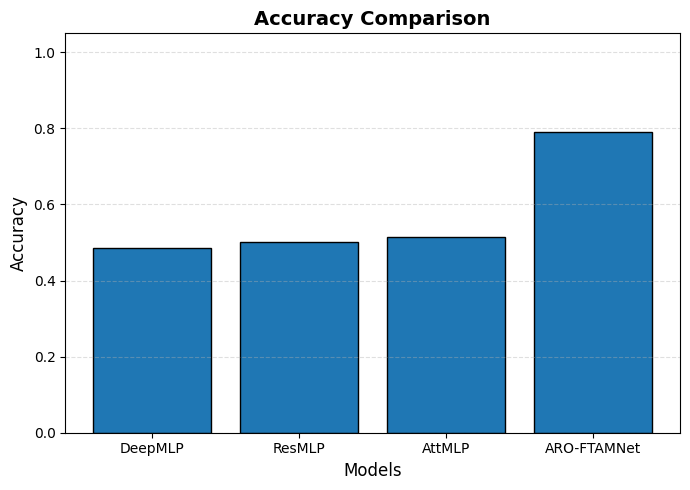

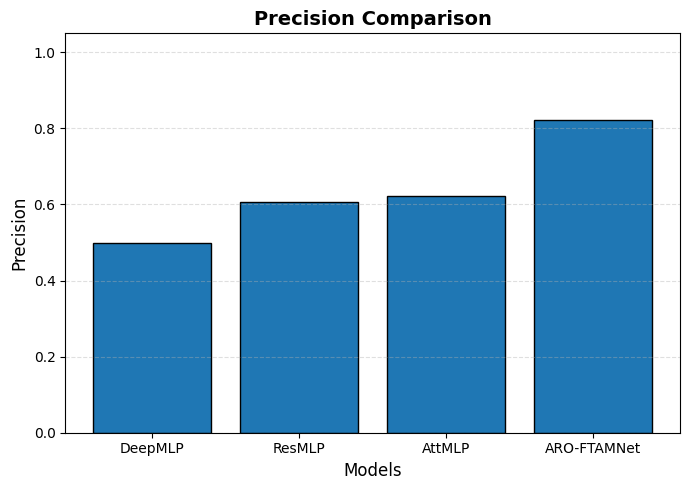

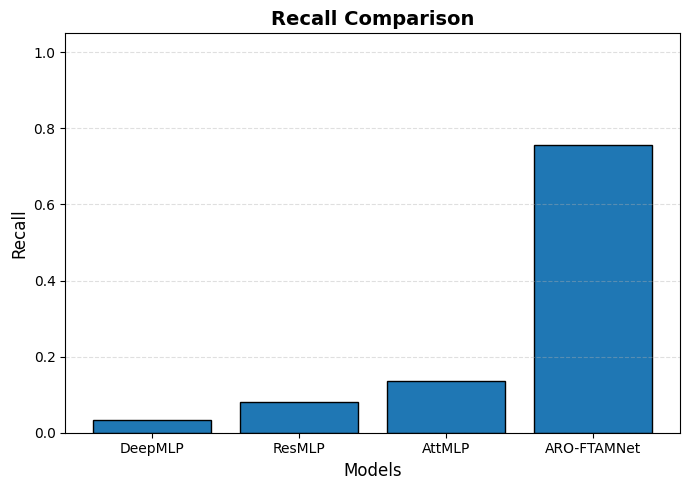

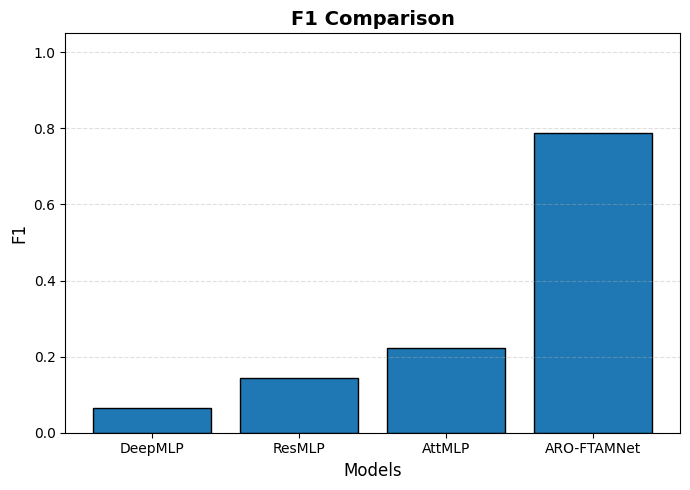

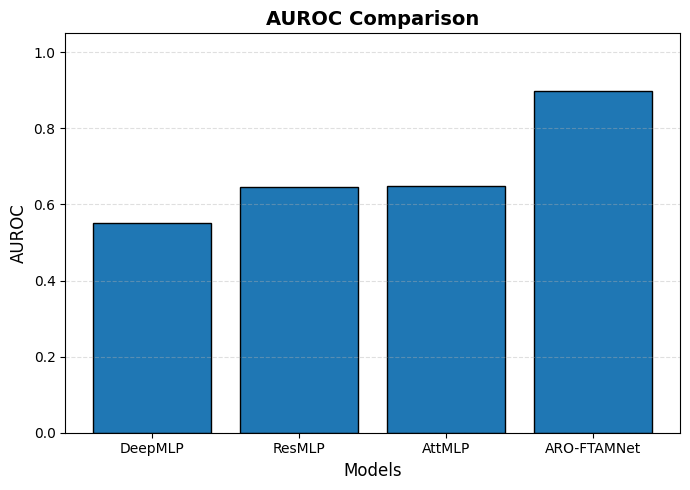

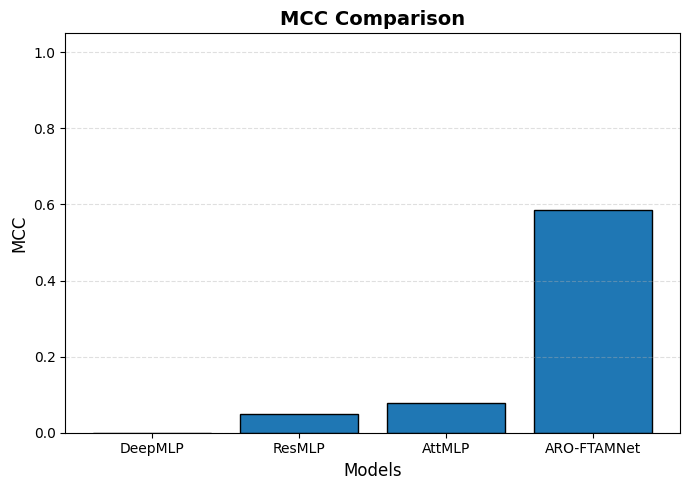

All metric comparison figures saved successfully.


In [126]:
# ============================================================
# INDIVIDUAL METRIC COMPARISON
# ============================================================

import os
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1", "AUROC", "MCC"]

for metric in metrics:

    plt.figure(figsize=(7,5))

    values = comparison[metric].astype(float)

    plt.bar(
        comparison["Model"],
        values,
        edgecolor="black"
    )

    plt.title(f"{metric} Comparison", fontsize=14, fontweight="bold")
    plt.xlabel("Models", fontsize=12)
    plt.ylabel(metric, fontsize=12)

    plt.ylim(0, 1.05)

    plt.grid(axis='y', linestyle='--', alpha=0.4)

    plt.tight_layout()

    filename = os.path.join(
        OUTPUT_DIR,
        f"{metric}_Comparison.tiff"
    )

    plt.savefig(
        filename,
        dpi=600,
        format="tiff",
        bbox_inches="tight"
    )

    plt.show()      # Display the image
    plt.close()     # Close the figure

print("All metric comparison figures saved successfully.")

In [127]:
# ============================================================
# ORGANIZE ALL OUTPUTS INTO A SINGLE FOLDER
# ============================================================

import os
import glob
import shutil

ROOT_DIR = "Final_Journal_Outputs"
FIG_DIR = os.path.join(ROOT_DIR, "Figures")
TAB_DIR = os.path.join(ROOT_DIR, "Tables")

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

# -------------------------------------------------------
# Move all TIFF figures
# -------------------------------------------------------

for file in glob.glob("*.tiff"):
    shutil.copy2(file, FIG_DIR)

# -------------------------------------------------------
# Move PNG figures (if any)
# -------------------------------------------------------

for file in glob.glob("*.png"):
    shutil.copy2(file, FIG_DIR)

# -------------------------------------------------------
# Move CSV tables
# -------------------------------------------------------

for file in glob.glob("*.csv"):
    shutil.copy2(file, TAB_DIR)

# -------------------------------------------------------
# Move Excel tables
# -------------------------------------------------------

for file in glob.glob("*.xlsx"):
    shutil.copy2(file, TAB_DIR)

print("Files Organized Successfully")

Files Organized Successfully


In [128]:
# ============================================================
# CREATE ZIP FILE
# ============================================================

import shutil

shutil.make_archive(
    "Final_Journal_Outputs",
    "zip",
    ROOT_DIR
)

print("="*60)
print("ZIP Created Successfully")
print("="*60)
print("Final_Journal_Outputs.zip")

ZIP Created Successfully
Final_Journal_Outputs.zip


In [129]:
# ============================================================
# VERIFY CONTENTS
# ============================================================

for root, dirs, files in os.walk(ROOT_DIR):

    print("\n", root)

    for f in sorted(files):
        print("   ", f)


 Final_Journal_Outputs

 Final_Journal_Outputs/Tables

 Final_Journal_Outputs/Figures


In [130]:
import os

for root, dirs, files in os.walk("."):
    if files:
        print("\n", root)
        for f in files:
            print("   ", f)


 .
    Scaler.pkl
    Best_Rabbit.pkl
    Best_ARO_Params.pkl
    FTAMNet_Best.keras
    Best_FTAMNet.keras
    best_rabbit.pkl
    Selected_Features.pkl
    Final_Journal_Outputs.zip
    ARO_FTAMNet_Final.keras
    ARO_FTAMNet_Journal_Outputs.zip
    FTAMNet_Final.keras
    __notebook__.ipynb

 ./Journal_Outputs
    Scaler.pkl
    AUC_Curve.tiff
    Recall_Comparison.tiff
    Confusion_Matrix.csv
    MCC_Comparison.tiff
    ConfusionMatrix_Comparison_Publication.tiff
    Performance_Comparison.xlsx
    Best_Rabbit.pkl
    Precision_Comparison.tiff
    Loss_Curve.tiff
    ROC_Probabilities.csv
    ROC_Comparison_All_Models.tiff
    PR_Comparison_All_Models.tiff
    Training_History.csv
    Complete_Model_Comparison.xlsx
    Final_Results.csv
    Radar_Chart.tiff
    Accuracy_Comparison.tiff
    Training_History.xlsx
    Grouped_Bar_Comparison.tiff
    Performance_Comparison.csv
    Selected_Features.pkl
    Final_Results.xlsx
    Confusion_Matrix.tiff
    ROC_Curve.tiff
    AUROC_Comp

In [131]:
# ============================================================
# COLLECT ALL FIGURES & TABLES (SAFE VERSION)
# ============================================================

import os
import shutil
from pathlib import Path

FINAL_DIR = "Final_Journal_Outputs"
FIG_DIR = os.path.join(FINAL_DIR, "Figures")
TAB_DIR = os.path.join(FINAL_DIR, "Tables")

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

image_ext = {".tiff", ".tif", ".png", ".jpg", ".jpeg"}
table_ext = {".csv", ".xlsx"}

# -------------------- Images --------------------

for file in Path(".").rglob("*"):

    if file.suffix.lower() in image_ext:

        destination = Path(FIG_DIR) / file.name

        # Skip if source and destination are identical
        if file.resolve() == destination.resolve():
            continue

        shutil.copy2(file, destination)

# -------------------- Tables --------------------

for file in Path(".").rglob("*"):

    if file.suffix.lower() in table_ext:

        destination = Path(TAB_DIR) / file.name

        if file.resolve() == destination.resolve():
            continue

        shutil.copy2(file, destination)

print("All files collected successfully.")

All files collected successfully.


In [132]:
print("="*60)
print("Figures")
print("="*60)

for f in sorted(os.listdir(FIG_DIR)):
    print(f)

print("\nTotal Figures :", len(os.listdir(FIG_DIR)))

print("\n"+"="*60)
print("Tables")
print("="*60)

for f in sorted(os.listdir(TAB_DIR)):
    print(f)

print("\nTotal Tables :", len(os.listdir(TAB_DIR)))

Figures
AUC_Curve.tiff
AUROC_Comparison.tiff
Accuracy_Comparison.tiff
Calibration_Curve.tiff
ConfusionMatrix_Comparison_Publication.tiff
Confusion_Matrix.tiff
F1_Comparison.tiff
Grouped_Bar_Comparison.tiff
Loss_Curve.tiff
MCC_Comparison.tiff
PR_Comparison_All_Models.tiff
Precision_Comparison.tiff
Precision_Recall_Curve.tiff
ROC_Comparison_All_Models.tiff
ROC_Curve.tiff
Radar_Chart.tiff
Recall_Comparison.tiff

Total Figures : 17

Tables
Complete_Model_Comparison.csv
Complete_Model_Comparison.xlsx
Confusion_Matrix.csv
Confusion_Matrix.xlsx
Final_Results.csv
Final_Results.xlsx
Performance_Comparison.csv
Performance_Comparison.xlsx
ROC_Probabilities.csv
ROC_Probabilities.xlsx
Training_History.csv
Training_History.xlsx

Total Tables : 12


In [133]:
import shutil

shutil.make_archive(
    "Final_Journal_Outputs",
    "zip",
    FINAL_DIR
)

print("ZIP created successfully.")

ZIP created successfully.


In [134]:
import os

for root, dirs, files in os.walk("Final_Journal_Outputs"):
    print(f"\n{root}")
    print(f"Number of files: {len(files)}")
    for f in files:
        print("   ", f)


Final_Journal_Outputs
Number of files: 0

Final_Journal_Outputs/Tables
Number of files: 12
    Confusion_Matrix.csv
    Performance_Comparison.xlsx
    ROC_Probabilities.csv
    Training_History.csv
    Complete_Model_Comparison.xlsx
    Final_Results.csv
    Training_History.xlsx
    Performance_Comparison.csv
    Final_Results.xlsx
    ROC_Probabilities.xlsx
    Complete_Model_Comparison.csv
    Confusion_Matrix.xlsx

Final_Journal_Outputs/Figures
Number of files: 17
    AUC_Curve.tiff
    Recall_Comparison.tiff
    MCC_Comparison.tiff
    ConfusionMatrix_Comparison_Publication.tiff
    Precision_Comparison.tiff
    Loss_Curve.tiff
    ROC_Comparison_All_Models.tiff
    PR_Comparison_All_Models.tiff
    Radar_Chart.tiff
    Accuracy_Comparison.tiff
    Grouped_Bar_Comparison.tiff
    Confusion_Matrix.tiff
    ROC_Curve.tiff
    AUROC_Comparison.tiff
    Calibration_Curve.tiff
    F1_Comparison.tiff
    Precision_Recall_Curve.tiff
